# 🎬 MovieLens Top-5 Movie Recommender: a Hybrid Collaborative-Filtering System

## 1. Objective (read this first)

**Business problem.** A movie-streaming service wants a *"Top 5 picks for you"* row on every user's home page. The user has already rated some movies; the system must use those ratings to recommend **five movies the user has not rated yet and is likely to watch *and* enjoy** (we define "enjoy" as a rating of **4.0 or higher** on the 0.5 to 5 scale).

**Machine-learning task.** Given a user's rating history, produce a ranked list of 5 unseen movies.
This is solved as a combination of two sub-problems, because a good "Top 5" has to answer two questions:

| Question | Signal used | Model |
|---|---|---|
| *How much would this user **like** movie *i*?* (rating prediction) | explicit ratings + movie metadata | bias model + matrix factorisation + item-kNN + user-kNN + content-based ridge, blended |
| *Would this user **watch** movie *i* at all?* (exposure / watch-likelihood) | which movies each user chose to rate | implicit-feedback matrix factorisation (iALS) |

**How the user provides their ratings.** As a simple dictionary `{movie title: rating}` (e.g. `{"Matrix, The (1999)": 5, "Alien (1979)": 4.5}`), or, for existing users, their stored history. The model scores *any* rating vector ("fold-in"), so a **brand-new user needs no re-training**.

**Requirements from the assignment and where they are met**

| Requirement | Where |
|---|---|
| Top-5 recommendations from a user's ratings | Steps 8 to 10 |
| Must use **collaborative filtering** | Step 6 (item-kNN, user-kNN, matrix factorisation) + Step 8.2 (implicit CF) |
| Consider a **hybrid** with content-based filtering for the **cold-start** problem | Step 7 (content model) and Step 8 (hybrid blend gated by item support) |
| Thoughtful **evaluation / metrics** (RMSE, MAE and more) | Step 4 and Steps 5 to 9: RMSE, MAE **and** ranking metrics (Precision/Recall/Hit/NDCG@5, coverage, popularity bias) |

## 2. Data understanding (summary; evidence in Step 2)

Dataset: **MovieLens `ml-latest-small`** (GroupLens, University of Minnesota).

| Fact | Value |
|---|---|
| Ratings | **100,836** (scale 0.5 to 5.0, half-star steps), 1996 to 2018 |
| Users | **610** (everyone has at least 20 ratings; no demographics) |
| Movies | **9,742** in the catalogue (9,724 rated, 18 never rated) |
| Matrix sparsity | **98.3 %** of user-movie cells are empty |
| Rating level | mean **3.50**; 48 % of ratings are 4 or higher; users differ a lot in how generous they are |
| Long tail | median movie has **3** ratings; 35 % have exactly **1**; the top 10 % of movies get **60 %** of all ratings |
| Side information | genres (all movies), release year (in the title), free-text user tags (only **16 %** of movies) |

**What this implies for the model** (details and evidence below):
1. Sparsity + a long tail means pure collaborative filtering is unreliable for rarely-rated movies, so we **blend in a content-based model** and trust each component according to how many ratings a movie has.
2. Users have very different rating habits, so we model **user and item biases first** and let the other models learn only the *residual* taste.
3. Users mostly rate what they *chose to watch* (exposure bias), so offline accuracy of a pure rating predictor is a poor guide to a good Top-5 list. We therefore add an **implicit "will they watch it?" model** and evaluate with **ranking metrics**, not just RMSE.

## 3. Approach in one picture

```
 ratings ──► bias model (mu + b_u + b_i) ──► residuals ──┬─► Matrix factorisation (ALS)  ─┐
                                                          ├─► Item-based kNN               ├─► weighted blend per item-support bucket ─► predicted rating r̂
 movie metadata (genres, decade, tags) ───────────────────┼─► Content-based ridge  ────────┤        (cold / mid / warm)
                                                          └─► User-based kNN  ─────────────┘
 who-rated-what (binary) ──► implicit ALS ──► watch-likelihood p̂
                                                                      final score = r̂ + β · p̂   →   Top-5 unseen movies
```

**Notebook roadmap:** 1 Setup, 2 Data understanding, 3 Data preparation, 4 Evaluation framework, 5 Baselines, 6 Collaborative filtering, 7 Content-based and cold start, 8 Hybrid model (+ model documentation), 9 Final training and test evaluation, 10 Recommendations in action, 11 Conclusions.

> **Protocol.** Each user's ratings are split **70 % train / 10 % validation / 20 % test**. All tuning uses *train → validation*. The test set is touched **once**, at the very end, after refitting on train + validation.


---
# Step 1: Setup
## 1.1 Imports, configuration and data location

In [3]:
import warnings, zipfile, time, re
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import nnls
from scipy.stats import spearmanr
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.model_selection import KFold

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 170)
pd.set_option("display.float_format", "{:.4f}".format)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

# --- locate the dataset (folder next to the notebook, or the zip file) ---
DATA_DIR = Path("ml-latest-small")
ZIP_CANDIDATES = [Path("ml-latest-small.zip"), Path("/mnt/user-data/uploads/ml-latest-small.zip")]
if not DATA_DIR.exists():
    for z in ZIP_CANDIDATES:
        if z.exists():
            zipfile.ZipFile(z).extractall(".")
            break
    else:
        raise FileNotFoundError("Place 'ml-latest-small/' (or the zip) next to this notebook.")
print("Data folder:", DATA_DIR.resolve())
print("Files:", sorted(p.name for p in DATA_DIR.iterdir()))
print(f"numpy {np.__version__} | pandas {pd.__version__}")

Data folder: C:\Users\USER\ml-latest-small
Files: ['README.txt', 'links.csv', 'movies.csv', 'ratings.csv', 'tags.csv']
numpy 1.26.4 | pandas 2.2.2


**What the code does.** Imports the libraries, fixes a random seed (`SEED = 42`) so every number in this notebook is reproducible, sets display options, and locates the data: it uses the folder `ml-latest-small/` next to the notebook, or unzips `ml-latest-small.zip` if only the zip is present.

**Why it matters.** Reproducibility and portability: anyone can re-run the notebook top-to-bottom. Only standard scientific Python is needed (NumPy, pandas, SciPy, scikit-learn, matplotlib, seaborn); all recommender algorithms are implemented here from scratch so each step is transparent.

**Reading the output.** The four expected files (`ratings`, `movies`, `tags`, `links`) are found.

**Decision.** Proceed to loading. (`links.csv` only holds IMDb/TMDb ids and is not needed for modelling.)

---
# Step 2: Data understanding (EDA)
## 2.1 Load the four files and check their integrity

In [6]:
ratings = pd.read_csv(DATA_DIR / "ratings.csv")
movies  = pd.read_csv(DATA_DIR / "movies.csv")
tags    = pd.read_csv(DATA_DIR / "tags.csv")
links   = pd.read_csv(DATA_DIR / "links.csv")

overview = pd.DataFrame({
    "rows":      [len(d) for d in (ratings, movies, tags, links)],
    "columns":   [", ".join(d.columns) for d in (ratings, movies, tags, links)],
    "null cells": [int(d.isna().sum().sum()) for d in (ratings, movies, tags, links)],
    "duplicate rows": [int(d.duplicated().sum()) for d in (ratings, movies, tags, links)],
}, index=["ratings", "movies", "tags", "links"])
display(overview)

display(ratings.head(3)); display(movies.head(3)); display(tags.head(3))

checks = {
    "users": ratings.userId.nunique(),
    "movies in catalogue": movies.movieId.nunique(),
    "movies with >=1 rating": ratings.movieId.nunique(),
    "movies never rated": int((~movies.movieId.isin(ratings.movieId)).sum()),
    "ratings pointing to unknown movie": int((~ratings.movieId.isin(movies.movieId)).sum()),
    "duplicate (user, movie) pairs": int(ratings.duplicated(["userId", "movieId"]).sum()),
    "min ratings by a user": int(ratings.groupby("userId").size().min()),
    "rating scale": f"{ratings.rating.min()} - {ratings.rating.max()} (step 0.5)",
    "date range": f"{pd.to_datetime(ratings.timestamp, unit='s').min().date()} to {pd.to_datetime(ratings.timestamp, unit='s').max().date()}",
}
display(pd.Series(checks, name="integrity check").to_frame())

,rows,columns,null cells,duplicate rows
ratings,100836,"userId, movieId, rating, timestamp",0,0
movies,9742,"movieId, title, genres",0,0
tags,3683,"userId, movieId, tag, timestamp",0,0
links,9742,"movieId, imdbId, tmdbId",8,0


,userId,movieId,rating,timestamp
0,1,1,4.0000,964982703
1,1,3,4.0000,964981247
2,1,6,4.0000,964982224


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance


,userId,movieId,tag,timestamp
0,2,60756,funny,1445714994
1,2,60756,Highly quotable,1445714996
2,2,60756,will ferrell,1445714992


,integrity check
users,610
movies in catalogue,9742
movies with >=1 rating,9724
movies never rated,18
ratings pointing to unknown movie,0
"duplicate (user, movie) pairs",0
min ratings by a user,20
rating scale,0.5 - 5.0 (step 0.5)
date range,1996-03-29 to 2018-09-24


**What the code does.** Loads the four CSVs and runs integrity checks: row counts, nulls, duplicates, whether every rating points to a known movie, the smallest per-user history, rating scale and date range.

**Why it matters.** A recommender silently fails on dirty keys (duplicate user-movie pairs, orphan ids). Checking first prevents wrong conclusions later.

**Reading the output.**
- **100,836 ratings** from **610 users** on **9,724 movies**; the catalogue has **9,742** movies, so **18 movies were never rated**. They can only ever be scored from content, a natural cold-start test case.
- No nulls in `ratings`/`movies`/`tags`, **no duplicate (user, movie) pairs**, no orphan movie ids. (`links.csv` has 8 missing TMDb ids, irrelevant here.)
- Every user has **at least 20 ratings** (a guarantee of the dataset), and ratings use half-star steps from 0.5 to 5.0.

**Decision.** The data is clean, so no rows are dropped. We index the **full 9,742-movie catalogue** (not just rated movies) so never-rated movies are handled properly later.

## 2.2 What do the ratings look like?

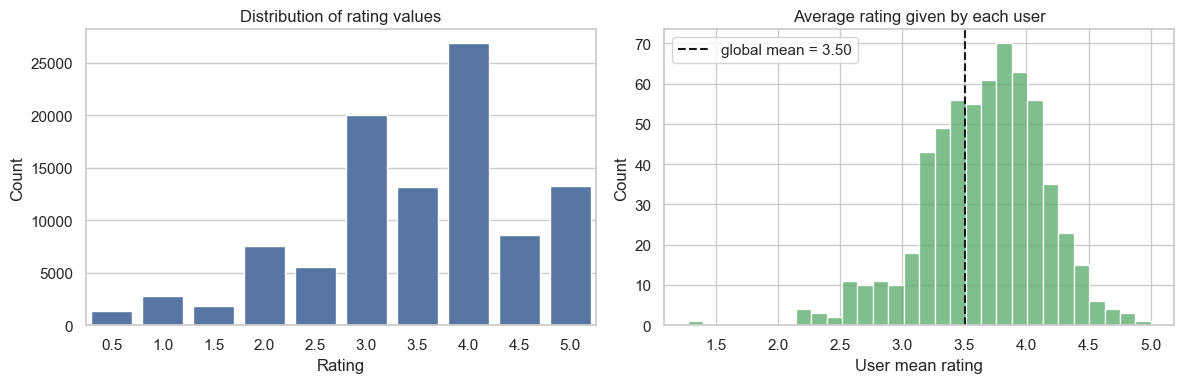

Global mean rating : 3.502   (median 3.5)
Share rated >= 4.0 : 48.2%
Share rated <= 2.0 : 13.4%
Share of whole-star ratings: 69.9%
User-mean std: 0.481 | min 1.27 | max 5.00


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x="rating", data=ratings, color="#4C72B0", ax=ax[0])
ax[0].set_title("Distribution of rating values"); ax[0].set_xlabel("Rating"); ax[0].set_ylabel("Count")
user_mean = ratings.groupby("userId").rating.mean()
sns.histplot(user_mean, bins=30, color="#55A868", ax=ax[1])
ax[1].axvline(ratings.rating.mean(), color="k", ls="--", label=f"global mean = {ratings.rating.mean():.2f}")
ax[1].set_title("Average rating given by each user"); ax[1].set_xlabel("User mean rating"); ax[1].legend()
plt.tight_layout(); plt.show()

print(f"Global mean rating : {ratings.rating.mean():.3f}   (median {ratings.rating.median()})")
print(f"Share rated >= 4.0 : {(ratings.rating >= 4).mean():.1%}")
print(f"Share rated <= 2.0 : {(ratings.rating <= 2).mean():.1%}")
print(f"Share of whole-star ratings: {(ratings.rating % 1 == 0).mean():.1%}")
print(f"User-mean std: {user_mean.std():.3f} | min {user_mean.min():.2f} | max {user_mean.max():.2f}")

**What the code does.** Plots the distribution of rating values and of each user's average rating, and prints summary statistics.

**Why it matters.** The rating scale and the skew of the data decide the choice of loss/metrics, the "like" threshold, and whether per-user bias correction is needed.

**Reading the output.**
- Ratings are **skewed positive**: mean **3.50**, median 3.5, and **48.2 %** are 4.0 or higher (only 13.4 % are 2.0 or lower). People mostly rate movies they chose and expected to like.
- Whole stars are used more than half stars (69.9 % whole).
- Users differ strongly in generosity: user-average ratings have a standard deviation of **0.48** and range from **1.27 to 5.00**.

**Decisions.**
1. **Model user and item biases explicitly first** (Step 5), because a 5.0 from a harsh rater and a 5.0 from a generous rater mean different things.
2. Define a **"liked" movie as rating ≥ 4.0** for the ranking metrics. That is roughly the top half of ratings and matches what a user would call a good recommendation.
3. Report **RMSE and MAE** for rating accuracy (the scale is ordinal with 10 levels, so treating it as regression is reasonable, as the assignment suggests), and **ranking metrics** for the Top-5 list.

## 2.3 How do users behave?

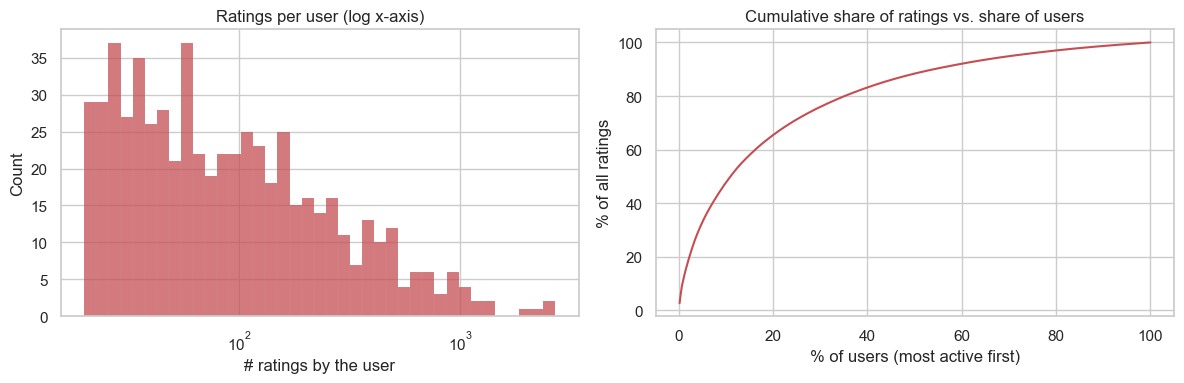

count    610.0000
mean     165.3000
std      269.5000
min       20.0000
25%       35.0000
50%       70.5000
75%      168.0000
max     2698.0000

Users with < 50 ratings : 36.9%
Top 10% most active users contribute 47.7% of all ratings


In [12]:
per_user = ratings.groupby("userId").size()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(per_user, bins=np.logspace(np.log10(20), np.log10(per_user.max()), 40), color="#C44E52", ax=ax[0])
ax[0].set_xscale("log"); ax[0].set_title("Ratings per user (log x-axis)"); ax[0].set_xlabel("# ratings by the user")
srt = np.sort(per_user.values)[::-1]
ax[1].plot(np.arange(1, len(srt) + 1) / len(srt) * 100, np.cumsum(srt) / srt.sum() * 100, color="#C44E52")
ax[1].set_title("Cumulative share of ratings vs. share of users"); ax[1].set_xlabel("% of users (most active first)"); ax[1].set_ylabel("% of all ratings")
plt.tight_layout(); plt.show()

print(per_user.describe().round(1).to_string())
print(f"\nUsers with < 50 ratings : {(per_user < 50).mean():.1%}")
print(f"Top 10% most active users contribute {srt[:int(0.1*len(srt))].sum()/srt.sum():.1%} of all ratings")

**What the code does.** Shows how many ratings each user contributed (log scale) and how concentrated activity is across users.

**Why it matters.** Users with very few ratings give collaborative filtering little to work with ("user cold start"), while a handful of power users can dominate training.

**Reading the output.**
- Strongly right-skewed: **median 70 ratings**, mean 165, maximum **2,698**.
- **36.9 %** of users have fewer than 50 ratings; the **top 10 %** of users supply **47.7 %** of all ratings.

**Decisions.**
- Use **regularisation that scales with the number of ratings** (ALS-WR, damping, shrinkage) so power users do not overfit and light users are not ignored.
- Evaluate **per user** (each user counts once in ranking metrics) and run a **segment analysis** by user activity in Step 9.4, because an average dominated by heavy users could hide poor performance for light users.

## 2.4 How are movies rated? (sparsity and the long tail)

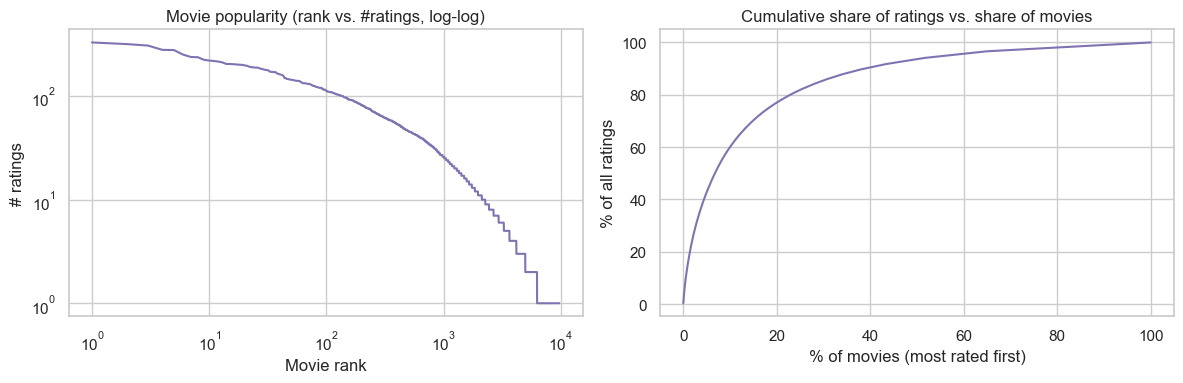

Matrix: 610 users x 9724 rated movies -> sparsity = 98.30%
count   9724.0000
mean      10.4000
std       22.4000
min        1.0000
25%        1.0000
50%        3.0000
75%        9.0000
max      329.0000
Movies with <=  1 ratings: 35.4%
Movies with <=  5 ratings: 66.4%
Movies with <= 10 ratings: 78.2%
Top 10% of movies receive 60.0% of all ratings
Spearman(popularity, mean rating) for movies with >=10 ratings: 0.251


In [15]:
per_item = ratings.groupby("movieId").size().sort_values(ascending=False)
n_users, n_items_rated = ratings.userId.nunique(), ratings.movieId.nunique()
sparsity = 1 - len(ratings) / (n_users * n_items_rated)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].loglog(np.arange(1, len(per_item) + 1), per_item.values, color="#8172B2")
ax[0].set_title("Movie popularity (rank vs. #ratings, log-log)"); ax[0].set_xlabel("Movie rank"); ax[0].set_ylabel("# ratings")
ax[1].plot(np.arange(1, len(per_item) + 1) / len(per_item) * 100, np.cumsum(per_item.values) / per_item.sum() * 100, color="#8172B2")
ax[1].set_title("Cumulative share of ratings vs. share of movies"); ax[1].set_xlabel("% of movies (most rated first)"); ax[1].set_ylabel("% of all ratings")
plt.tight_layout(); plt.show()

print(f"Matrix: {n_users} users x {n_items_rated} rated movies -> sparsity = {sparsity:.2%}")
print(per_item.describe().round(1).to_string())
for t in (1, 5, 10):
    print(f"Movies with <= {t:>2} ratings: {(per_item <= t).mean():.1%}")
print(f"Top 10% of movies receive {per_item.iloc[:int(0.1*len(per_item))].sum()/per_item.sum():.1%} of all ratings")
stats = ratings.groupby("movieId").rating.agg(["mean", "count"])
rho, _ = spearmanr(stats[stats["count"] >= 10]["count"], stats[stats["count"] >= 10]["mean"])
print(f"Spearman(popularity, mean rating) for movies with >=10 ratings: {rho:.3f}")

**What the code does.** Plots the popularity of movies (rank vs. number of ratings on log-log axes, and the cumulative share of ratings) and computes sparsity and long-tail statistics.

**Why it matters.** This is the central data-quality issue for recommenders: how much evidence exists per movie.

**Reading the output.**
- The matrix is **98.30 % empty** (610 × 9,724 cells, only 100,836 observed).
- A classic **long tail**: the median movie has **3 ratings**; **35.4 %** of movies have exactly one rating, **66.4 %** have 5 or fewer. The **top 10 %** of movies capture **60 %** of all ratings.
- Popular movies are slightly better rated (Spearman **0.25** between rating count and mean rating for movies with at least 10 ratings).

**Decisions.**
1. For most movies, similarity-based CF has too little evidence. We use **shrinkage/damping** toward the bias model and add a **content-based model** whose weight is *higher for rarely-rated movies* (Steps 7 and 8).
2. Popularity correlates with being liked, so a **popularity baseline will be strong** and must be beaten honestly (Step 5).
3. A naive "highest predicted rating" ranking would promote obscure movies with one lucky 5-star rating, so ranking needs a "will they watch it" signal (Step 8.2).

## 2.5 Genres and release years

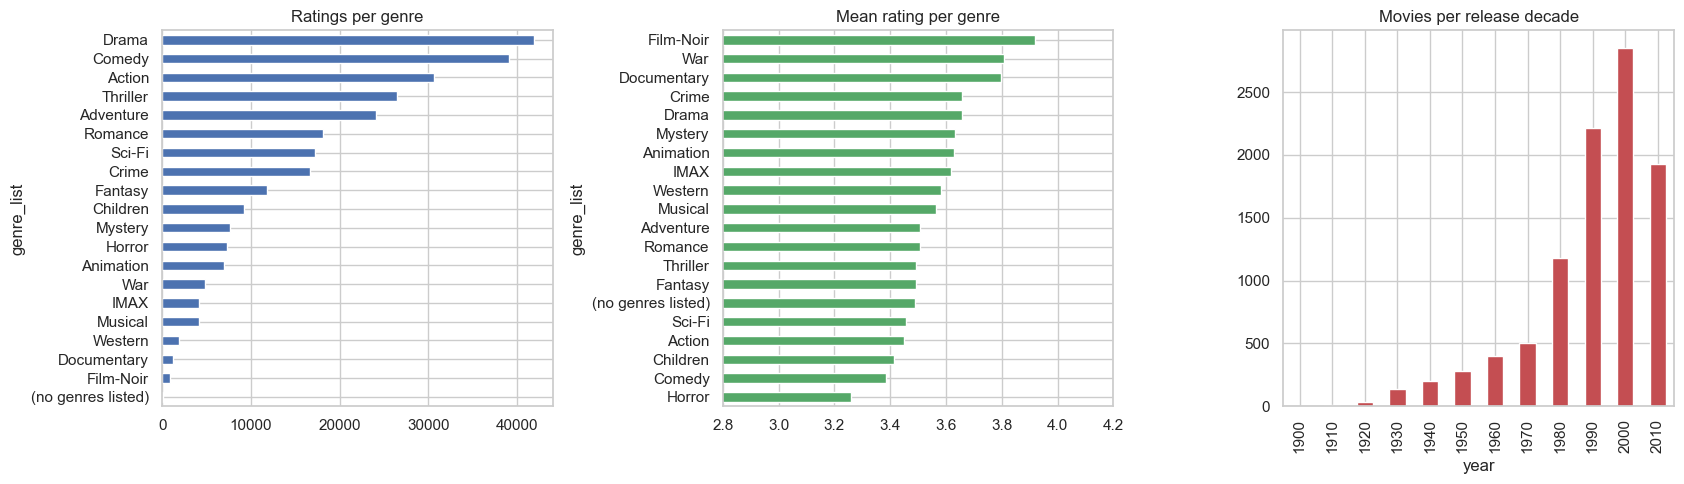

Genres per movie: {'mean': 2.27, '50%': 2.0, 'max': 10.0}
Movies without a parsable year: 13 | without genres: 34


,movies,ratings,mean_rating
genre_list,,,
Drama,4361,41928,3.6562
Comedy,3756,39053,3.3847
Action,1828,30635,3.4480
Thriller,1894,26452,3.4937
Adventure,1263,24161,3.5086
Romance,1596,18124,3.5065


In [18]:
m = movies.copy()
m["year"] = m.title.str.extract(r"\((\d{4})\)\s*$")[0].astype(float)
m["genre_list"] = m.genres.str.split("|")
g = m.explode("genre_list").merge(ratings[["movieId", "rating"]], on="movieId", how="left")
genre_tbl = g.groupby("genre_list").agg(movies=("movieId", "nunique"), ratings=("rating", "count"), mean_rating=("rating", "mean")).sort_values("ratings", ascending=False)

fig, ax = plt.subplots(1, 3, figsize=(17, 5))
genre_tbl["ratings"].plot.barh(ax=ax[0], color="#4C72B0"); ax[0].invert_yaxis(); ax[0].set_title("Ratings per genre")
genre_tbl.sort_values("mean_rating")["mean_rating"].plot.barh(ax=ax[1], color="#55A868"); ax[1].set_title("Mean rating per genre"); ax[1].set_xlim(2.8, 4.2)
(m.year.dropna() // 10 * 10).astype(int).value_counts().sort_index().plot.bar(ax=ax[2], color="#C44E52"); ax[2].set_title("Movies per release decade")
plt.tight_layout(); plt.show()

print("Genres per movie:", m.genre_list.str.len().describe()[["mean", "50%", "max"]].round(2).to_dict())
print("Movies without a parsable year:", int(m.year.isna().sum()), "| without genres:", int((m.genres == "(no genres listed)").sum()))
display(genre_tbl.head(6))

**What the code does.** Parses the release year from each title (`"Toy Story (1995)"`), splits the pipe-separated genres, and plots ratings per genre, mean rating per genre and movies per release decade.

**Why it matters.** Genres and years are the metadata available for **every** movie, including never-rated ones, so they are the backbone of the content-based part of the hybrid.

**Reading the output.**
- Drama (4,361 movies, 41,928 ratings) and Comedy dominate; movies carry on average **2.27 genres**.
- Genres differ in how well they are rated (e.g. Drama averages **3.66**, Comedy **3.38**), so genre carries real preference signal.
- Only **13 movies** have no parsable year and **34** have no genre label; the right-hand chart shows the spread of release decades.

**Decisions.** Encode genres as a multi-hot vector and the release **decade** as a categorical feature (unknown year gets its own column) rather than a raw year, since taste changes by era in steps, not linearly. Movies without a genre simply get an all-zero genre vector.

## 2.6 User tags and timing

Tag applications: 3,683 by 58 users on 1,572 movies (16.1% of the catalogue)
Most frequent tags: {'in netflix queue': 131, 'atmospheric': 41, 'funny': 24, 'superhero': 24, 'thought-provoking': 24, 'surreal': 24, 'disney': 23, 'sci-fi': 23, 'quirky': 22, 'religion': 22, 'dark comedy': 21, 'suspense': 21}


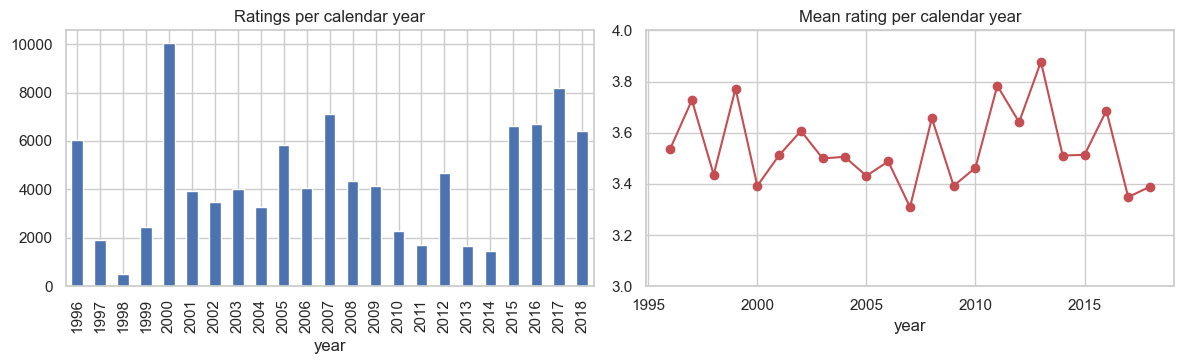

In [21]:
tag_per_movie = tags.groupby("movieId").size()
print(f"Tag applications: {len(tags):,} by {tags.userId.nunique()} users on {tags.movieId.nunique():,} movies "
      f"({tags.movieId.nunique()/len(movies):.1%} of the catalogue)")
print("Most frequent tags:", tags.tag.str.lower().value_counts().head(12).to_dict())

r = ratings.assign(year=pd.to_datetime(ratings.timestamp, unit="s").dt.year)
yr = r.groupby("year").agg(n=("rating", "size"), mean=("rating", "mean"))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
yr["n"].plot.bar(ax=ax[0], color="#4C72B0"); ax[0].set_title("Ratings per calendar year")
yr["mean"].plot(ax=ax[1], marker="o", color="#C44E52"); ax[1].set_title("Mean rating per calendar year"); ax[1].set_ylim(3, 4)
plt.tight_layout(); plt.show()

**What the code does.** Summarises the user-generated tags and plots rating volume and mean rating per calendar year.

**Why it matters.** Tags could give richer movie descriptors than genres, but only if coverage is adequate; timestamps would matter if tastes drift.

**Reading the output.**
- **3,683 tag applications** by only **58 users**, covering **1,572 movies (16.1 %)**. Coverage is sparse and the most frequent tag is the non-informative "in netflix queue".
- Rating activity is bursty (e.g. 10,061 ratings in 2000 vs. 507 in 1998) while the yearly mean stays in a narrow band (about 3.3 to 3.9), so there is no strong global drift.

**Decisions.**
- Use tags **only as a light, low-dimensional addition** (TF-IDF → 20-dim SVD), tested by ablation in Step 7.1 to see whether they really help.
- **Ignore time** in the model (no strong drift; a random per-user split is used). Temporal modelling is listed as future work.

---
# Step 3: Data preparation
## 3.1 Clean metadata and build the user / movie index

In [24]:
movies = m.drop(columns=["genre_list"]).copy()           # keeps parsed 'year'
user_ids  = np.sort(ratings.userId.unique())
movie_ids = np.sort(movies.movieId.values)                # FULL catalogue (also never-rated movies)
u2i = {u: i for i, u in enumerate(user_ids)}
m2i = {mid: i for i, mid in enumerate(movie_ids)}
ratings["u"] = ratings.userId.map(u2i).astype(int)
ratings["i"] = ratings.movieId.map(m2i).astype(int)
n_users, n_items = len(user_ids), len(movie_ids)
movies = movies.set_index("movieId").loc[movie_ids].reset_index()
titles, genres_str = movies.title.values, movies.genres.values

def find_movie(query, top=5):
    """Search the catalogue by (part of) a title; most-rated matches first."""
    hit = movies[movies.title.str.contains(query, case=False, regex=False)].copy()
    hit["n_ratings"] = hit.movieId.map(ratings.groupby("movieId").size()).fillna(0).astype(int)
    return hit.sort_values("n_ratings", ascending=False).head(top)[["movieId", "title", "genres", "n_ratings"]]

print(f"{n_users} users x {n_items} movies in the index (catalogue incl. {int((~movies.movieId.isin(ratings.movieId)).sum())} never-rated movies)")
display(find_movie("Matrix"))

610 users x 9742 movies in the index (catalogue incl. 18 never-rated movies)


,movieId,title,genres,n_ratings
1939,2571,"Matrix, The (1999)",Action|Sci-Fi|Thriller,278
4351,6365,"Matrix Reloaded, The (2003)",Action|Adventure|Sci-Fi|Thriller|IMAX,96
4639,6934,"Matrix Revolutions, The (2003)",Action|Adventure|Sci-Fi|Thriller|IMAX,79
5669,27660,"Animatrix, The (2003)",Action|Animation|Drama|Sci-Fi,20


**What the code does.** Keeps the parsed `year`, builds integer indices for users (0..609) and movies (0..9741), attaches them to the ratings, and defines `find_movie()`, a helper to search titles (used later to let a user supply ratings by title).

**Why it matters.** Matrix-based algorithms need contiguous integer ids. Indexing the **whole catalogue** keeps never-rated movies in the model, which is essential for the cold-start analysis.

**Reading the output.** The index is 610 × 9,742. The search example shows that e.g. "Matrix" resolves to *The Matrix (1999)* with 278 ratings first.

**Decision.** All later steps work on these indices; the title lookup returns the most-rated match so user-supplied titles resolve to the well-known film.

## 3.2 Train / validation / test split (per user)

In [27]:
def split_per_user(df, val_frac=0.10, test_frac=0.20, seed=SEED):
    """Random per-user hold-out: every user keeps ~70% train / 10% validation / 20% test."""
    rng = np.random.default_rng(seed)
    part = np.empty(len(df), dtype=object)
    for _, idx in df.groupby("u").indices.items():
        idx = rng.permutation(idx); n = len(idx)
        n_test, n_val = max(1, round(n * test_frac)), max(1, round(n * val_frac))
        part[idx[:n_test]] = "test"; part[idx[n_test:n_test + n_val]] = "val"; part[idx[n_test + n_val:]] = "train"
    return part

ratings["split"] = split_per_user(ratings)
tr, va, te = (ratings[ratings.split == s].copy() for s in ("train", "val", "test"))
trva = ratings[ratings.split != "test"].copy()

train_items = set(tr.i)
summary = pd.DataFrame({
    "ratings": [len(tr), len(va), len(te)],
    "share": [len(tr)/len(ratings), len(va)/len(ratings), len(te)/len(ratings)],
    "users covered": [tr.u.nunique(), va.u.nunique(), te.u.nunique()],
    "pairs on items unseen in train": [0, (~va.i.isin(train_items)).mean(), (~te.i.isin(train_items)).mean()],
    "relevant (>=4) ratings": [(tr.rating >= 4).sum(), (va.rating >= 4).sum(), (te.rating >= 4).sum()],
}, index=["train", "validation", "test"])
display(summary)
print("Smallest per-user train/val/test sizes:",
      tr.groupby("u").size().min(), va.groupby("u").size().min(), te.groupby("u").size().min())

,ratings,share,users covered,pairs on items unseen in train,relevant (>=4) ratings
train,70579,0.6999,610,0.0000,33934
validation,10093,0.1001,610,0.0429,4912
test,20164,0.2000,610,0.0444,9734


Smallest per-user train/val/test sizes: 14 2 4


**What the code does.** For **every user separately**, randomly assigns ~70 % of their ratings to *train*, ~10 % to *validation* and ~20 % to *test* (at least one validation and one test rating each). It then verifies sizes, user coverage and how many validation/test pairs involve movies never seen in training.

**Why it matters.** The honest question is *"can we predict what a known user will rate next?"*, so each user must appear in training with enough history **and** in the evaluation sets. Validation is used for **all** tuning; **test is held back for one final evaluation**, which prevents optimistic, over-tuned results.

**Reading the output.**
- 70,579 train / 10,093 validation / 20,164 test ratings; **all 610 users appear in all three sets** (smallest user has 14 / 2 / 4 ratings).
- **4.3 % of validation** and **4.4 % of test** ratings are on movies with **zero** training ratings, i.e. genuine item cold-start cases, and 1,164 catalogue movies have no training rating at all.
- Relevant (≥ 4) ratings: 4,912 in validation and 9,734 in test.

**Decisions.**
- Keep this random per-user split (a temporal split is a valuable extension, but tags/time drift are weak here).
- Note for later: the **test set has twice as many hold-out ratings per user as validation**, so absolute Top-5 scores will be *higher* on test than on validation. Models must be compared **within** the same set, not across them.

## 3.3 Rating matrices

In [30]:
def to_dense(df):
    R = np.zeros((n_users, n_items), dtype=np.float32)
    R[df.u.values, df.i.values] = df.rating.values
    return R, R > 0

R_tr, M_tr = to_dense(tr)          # used for tuning
R_trva, M_trva = to_dense(trva)    # used for the final fit (train + validation)
cnt_tr, cnt_trva = M_tr.sum(0), M_trva.sum(0)
print(f"Dense matrix shape {R_tr.shape} | {R_tr.nbytes/1e6:.0f} MB each | train density {M_tr.mean():.3%}")
print(f"Items with zero train ratings: {(cnt_tr == 0).sum()} of {n_items}")

Dense matrix shape (610, 9742) | 24 MB each | train density 1.188%
Items with zero train ratings: 1164 of 9742


**What the code does.** Converts the rating tables into dense `users × movies` matrices (`R` = ratings, `M` = "was rated" mask): one built from *train* (for tuning) and one from *train + validation* (for the final fit).

**Why it matters.** Dense matrices make every algorithm a few vectorised NumPy operations. At 610 × 9,742 they are small enough (24 MB each) that dense is both simpler and faster than sparse.

**Reading the output.** Training density is **1.19 %**, consistent with the 98.3 % sparsity seen in EDA.

**Decision.** Use dense float32 matrices throughout; `M_tr` / `cnt_tr` (ratings per movie in train) are used to define item support and to hide already-seen movies when ranking.

## 3.4 Content features for the content-based model

In [33]:
# --- genres (multi-hot) ---
G = movies.genres.str.get_dummies("|").drop(columns=["(no genres listed)"], errors="ignore")
# --- release decade (one-hot, unknown year gets its own column) ---
bins = [0, 1949, 1959, 1969, 1979, 1989, 1999, 2009, 2030]
decade = pd.cut(movies.year, bins, labels=["<=1949", "50s", "60s", "70s", "80s", "90s", "00s", "10s"])
Dm = pd.get_dummies(decade, dummy_na=True).astype(np.float32)
# --- user tags -> TF-IDF -> truncated SVD (dense semantic descriptors) ---
tag_docs = (tags.assign(tag=tags.tag.str.lower().str.strip()).groupby("movieId").tag.apply(list)
            .reindex(movie_ids).apply(lambda d: d if isinstance(d, list) else []))
tfidf = TfidfVectorizer(analyzer=lambda doc: doc, min_df=2)
T = tfidf.fit_transform(tag_docs)
svd = TruncatedSVD(n_components=20, random_state=SEED)
T20 = svd.fit_transform(T)
T20 = T20 / (np.linalg.norm(T20, axis=1, keepdims=True) + 1e-9)

X_genre, X_decade, X_tags = G.values.astype(np.float32), 0.5 * Dm.values.astype(np.float32), T20.astype(np.float32)
X_content = np.hstack([X_genre, X_decade, X_tags]).astype(np.float32)

print(f"genre cols {X_genre.shape[1]} | decade cols {X_decade.shape[1]} | tag-SVD cols {X_tags.shape[1]}  ->  X_content {X_content.shape}")
print(f"Tag vocabulary kept (min_df=2): {T.shape[1]} | movies with >=1 tag: {(T.getnnz(axis=1) > 0).sum()} | SVD explained variance: {svd.explained_variance_ratio_.sum():.1%}")

genre cols 19 | decade cols 9 | tag-SVD cols 20  ->  X_content (9742, 48)
Tag vocabulary kept (min_df=2): 542 | movies with >=1 tag: 1343 | SVD explained variance: 24.4%


**What the code does.** Builds one numeric descriptor per movie from three blocks: (1) **genres** multi-hot (19 columns), (2) **release decade** one-hot (8 decades + unknown), scaled by 0.5, and (3) **user tags** → TF-IDF → **20-dimensional SVD** (L2-normalised).

**Why it matters.** These features exist for **every** movie, including ones with zero ratings, so a model built on them can still score brand-new movies. That is exactly what collaborative filtering cannot do (the cold-start problem named in the assignment).

**Reading the output.** Final matrix **9,742 × 48** (19 + 9 + 20). Only 1,343 movies have tags and the 20 SVD components explain 24.4 % of tag variance, so tags are a weak, partial signal, which is why they are compressed and down-weighted.

**Decision.** Keep all three blocks for now; Step 7.1 tests whether decade and tags actually improve predictions. (Tag text is item metadata, not ratings, so using all tags does not leak test ratings.)

---
# Step 4: Evaluation framework
## 4.1 Rating-accuracy metrics and Top-5 ranking metrics (with sanity checks)

In [36]:
K_TOP, REL_THR = 5, 4.0

def rating_metrics(P, df):
    """RMSE / MAE of predicted ratings (clipped to the valid 0.5-5 range) on the pairs in `df`."""
    p = np.clip(P[df.u.values, df.i.values], 0.5, 5.0); y = df.rating.values
    return {"RMSE": float(np.sqrt(np.mean((p - y) ** 2))), "MAE": float(np.mean(np.abs(p - y)))}

def topn_eval(P, seen_mask, test_df, item_count, k=K_TOP, thr=REL_THR):
    """Top-k ranking quality. P = score matrix (users x items). Movies the user already rated (`seen_mask`)
    are never recommended. A recommendation is a hit if the user rated that movie >= thr in `test_df`."""
    S = np.array(P, dtype=np.float32)
    S[seen_mask] = -np.inf
    top = np.argpartition(-S, k, axis=1)[:, :k]
    top = np.take_along_axis(top, np.argsort(-np.take_along_axis(S, top, 1), axis=1), 1)
    rel = np.zeros(S.shape, dtype=bool)
    t = test_df[test_df.rating >= thr]; rel[t.u.values, t.i.values] = True
    n_rel, hits = rel.sum(1), np.take_along_axis(rel, top, 1)
    disc = 1 / np.log2(np.arange(2, k + 2))
    ideal = np.array([disc[:min(n, k)].sum() for n in n_rel])
    per_user = pd.DataFrame({"P@5": hits.mean(1), "R@5": hits.sum(1) / np.maximum(n_rel, 1),
                             "Hit@5": hits.any(1).astype(float), "NDCG@5": (hits * disc).sum(1) / np.maximum(ideal, 1e-12),
                             "n_rel": n_rel})
    per_user = per_user[per_user.n_rel > 0]
    summary = per_user[["P@5", "R@5", "Hit@5", "NDCG@5"]].mean().to_dict()
    summary["Coverage"] = len(np.unique(top)) / S.shape[1]
    summary["AvgLogPop"] = float(np.log1p(item_count[top]).mean())
    return summary, per_user, top

def edge_check(grid, best, params):
    """Report whether the winning value of each tuned parameter sits on the border of its search grid."""
    edge = [f"{p}={best[p]:g}" for p in params if best[p] in (grid[p].min(), grid[p].max())]
    print("Grid-edge check:", ("best value is ON the grid edge for " + ", ".join(edge)) if edge else "best value is interior for every parameter -> grid wide enough")

def log_result(store, name, P_rating=None, P_rank=None, df=va, seen=M_tr, cnt=cnt_tr):
    """Evaluate one model and append a row to `store` (rating metrics if P_rating, ranking metrics always)."""
    row = {"Model": name}
    if P_rating is not None:
        row.update(rating_metrics(P_rating, df))
    s, _, _ = topn_eval(P_rank if P_rank is not None else P_rating, seen, df, cnt)
    row.update(s); store.append(row)

# ---- sanity-check the metric code with an oracle and a random scorer ----
oracle = np.zeros((n_users, n_items), np.float32); oracle[va.u.values, va.i.values] = va.rating.values
rand = np.random.default_rng(SEED).random((n_users, n_items))
for name, P in [("oracle (knows the answers)", oracle), ("random", rand)]:
    s, _, _ = topn_eval(P, M_tr, va, cnt_tr)
    print(f"{name:<28} P@5={s['P@5']:.3f}  R@5={s['R@5']:.3f}  Hit@5={s['Hit@5']:.3f}  NDCG@5={s['NDCG@5']:.3f}  coverage={s['Coverage']:.1%}")

oracle (knows the answers)   P@5=0.733  R@5=0.773  Hit@5=1.000  NDCG@5=1.000  coverage=13.3%
random                       P@5=0.000  R@5=0.000  Hit@5=0.002  NDCG@5=0.000  coverage=26.8%


**What the code does.** Defines the two evaluation tools used everywhere afterwards:
- `rating_metrics`: **RMSE** and **MAE** of predicted ratings (predictions clipped to 0.5 to 5).
- `topn_eval`: for each user, hides movies already rated, takes the **Top-5** by score and compares with the held-out movies the user rated ≥ 4. It reports **Precision@5, Recall@5, Hit-rate@5, NDCG@5**, plus **catalogue coverage** (share of the catalogue ever recommended) and **average log-popularity** of recommended movies (a popularity-bias indicator). Also `edge_check`, which warns when a tuned value lands on the border of its search grid.

**Why it matters.** RMSE alone can reward a model that is accurate on average but ranks poorly, while the product shows a **Top-5 list**, so ranking quality is the metric that matches the business goal. Coverage and popularity expose models that "game" the metric by recommending only blockbusters.

**Reading the output (sanity check).** An **oracle** that knows the answers gets Hit@5 = 1.00 and NDCG@5 = 1.00 (its Precision@5 is 0.73 and not 1.0, because many users have fewer than five relevant validation ratings, so P@5 has a ceiling). A **random** scorer gets about 0, with Hit@5 of 0.002. The metric code therefore behaves correctly at both extremes.

**Decisions.**
- **NDCG@5** is the primary ranking metric (rewards putting hits near the top); **RMSE** the primary rating metric.
- Caveat to remember: unrated movies are treated as "not relevant", but a user may well have liked them. Offline metrics are therefore **conservative** and favour popular items; this is why we also report coverage and popularity.

---
# Step 5: Baselines (the bar every model has to clear)
## 5.1 Global mean, damped bias model, popularity and random

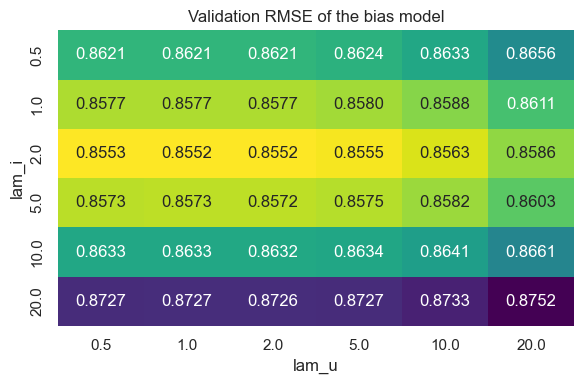

Best: lambda_i=2, lambda_u=1 -> RMSE 0.8552, MAE 0.6600
Grid-edge check: best value is interior for every parameter -> grid wide enough


,RMSE,MAE,P@5,R@5,Hit@5,NDCG@5,Coverage,AvgLogPop
Model,,,,,,,,
Global mean,1.0438,0.8290,0.0003,0.0001,0.0017,0.0003,0.2680,1.3331
Bias model (mu + b_u + b_i),0.8552,0.6600,0.0021,0.0006,0.0103,0.0018,0.0009,1.6113
Popularity (most rated),NaN,NaN,0.0757,0.0692,0.3029,0.0946,0.0023,5.2768
Random,NaN,NaN,0.0003,0.0001,0.0017,0.0003,0.2680,1.3331


In [39]:
val_results = []

# (a) Global mean predictor
P_global = np.full((n_users, n_items), R_tr[M_tr].mean(), dtype=np.float32)
log_result(val_results, "Global mean", P_global, P_rank=rand)       # no personalisation -> random ranking

# (b) Damped bias model:  r_ui = mu + b_u + b_i   (shrunk towards 0 by lambda_i / lambda_u)
def fit_bias(R, M, lam_i=10.0, lam_u=15.0, n_iter=10):
    mu = R[M].mean(); bu = np.zeros(R.shape[0], np.float32)
    for _ in range(n_iter):
        bi = (M * (R - mu - bu[:, None])).sum(0) / (M.sum(0) + lam_i)
        bu = (M * (R - mu - bi)).sum(1) / (M.sum(1) + lam_u)
    return float(mu), bi.astype(np.float32), float(lam_u)

def row_bias(R, M, mu, bi, lam_u):
    """User bias of arbitrary rating rows given the item biases (also used for brand-new users)."""
    return ((M * (R - mu - bi)).sum(1) / (M.sum(1) + lam_u)).astype(np.float32)

rows = []
for li in (0.5, 1, 2, 5, 10, 20):
    for lu in (0.5, 1, 2, 5, 10, 20):
        mu_, bi_, _ = fit_bias(R_tr, M_tr, li, lu); bu_ = row_bias(R_tr, M_tr, mu_, bi_, lu)
        rows.append({"lam_i": li, "lam_u": lu, **rating_metrics(mu_ + bi_[None, :] + bu_[:, None], va)})
bias_grid = pd.DataFrame(rows)
best_bias = bias_grid.loc[bias_grid.RMSE.idxmin()]
BIAS_LAM_I, BIAS_LAM_U = float(best_bias.lam_i), float(best_bias.lam_u)

plt.figure(figsize=(6, 4))
sns.heatmap(bias_grid.pivot(index="lam_i", columns="lam_u", values="RMSE"), annot=True, fmt=".4f", cmap="viridis_r", cbar=False)
plt.title("Validation RMSE of the bias model"); plt.tight_layout(); plt.show()
print(f"Best: lambda_i={BIAS_LAM_I:g}, lambda_u={BIAS_LAM_U:g} -> RMSE {best_bias.RMSE:.4f}, MAE {best_bias.MAE:.4f}")
edge_check(bias_grid, best_bias, ["lam_i", "lam_u"])

mu, b_i, lam_u_fit = fit_bias(R_tr, M_tr, BIAS_LAM_I, BIAS_LAM_U)
b_u = row_bias(R_tr, M_tr, mu, b_i, lam_u_fit)
P_bias = mu + b_i[None, :] + b_u[:, None]

# (c) Non-personalised ranking baselines
P_pop = np.tile(cnt_tr.astype(np.float32), (n_users, 1))                         # most-rated movies first
log_result(val_results, "Bias model (mu + b_u + b_i)", P_bias)
log_result(val_results, "Popularity (most rated)", None, P_rank=P_pop)
log_result(val_results, "Random", None, P_rank=rand)
display(pd.DataFrame(val_results).set_index("Model"))

**What the code does.**
- **Global mean** predictor (everyone gets 3.50).
- **Bias model** `r̂ = μ + b_u + b_i`, with user and movie offsets *shrunk toward zero* (λ_i, λ_u) so movies with 1 rating don't get extreme biases. λ's are tuned on validation over a 6 × 6 grid.
- **Popularity** (rank by number of ratings) and **Random** as non-personalised ranking baselines.

**Why it matters.** Any complex model must beat these; otherwise the complexity is not justified. Popularity in particular is a famously hard baseline in offline recommender evaluation.

**Reading the output.**
- Global mean: RMSE **1.044**, MAE 0.829. The bias model cuts this to RMSE **0.8552**, MAE **0.6600** (best λ_i = 2, λ_u = 1; the winners are interior to the grid, so the grid is wide enough).
- For ranking, the bias model is useless (NDCG@5 0.002; it only knows *averages*, not who watches what, and recommends just 9 distinct movies), whereas **Popularity is strong: P@5 = 0.076, Hit@5 = 30 %, NDCG@5 = 0.095**, yet it recommends only **22 distinct movies** (0.2 % of the catalogue) to all 610 users, so it is not personalised at all.

**Decisions.** Use the tuned bias model as the *foundation* of every later model. The targets to beat: **RMSE 0.8552** and **NDCG@5 0.095**.

---
# Step 6: Collaborative filtering
All CF models below learn from the **residuals** left over after the bias model, i.e. the part of a rating that is *not* explained by "this user is generous" and "this movie is good".
## 6.1 Residual matrix

In [42]:
E_tr = (M_tr * (R_tr - mu - b_i - b_u[:, None])).astype(np.float32)   # residual matrix (0 where unrated)
res_vals = E_tr[M_tr]
print(f"Residual matrix: mean {res_vals.mean():+.4f}, std {res_vals.std():.4f}, |res|>1 for {(np.abs(res_vals) > 1).mean():.1%} of ratings")
print(f"Baseline RMSE on the *training* ratings: {np.sqrt((res_vals ** 2).mean()):.4f}")

Residual matrix: mean -0.0002, std 0.7976, |res|>1 for 18.5% of ratings
Baseline RMSE on the *training* ratings: 0.7976


**What the code does.** Subtracts the bias model's prediction from every training rating, leaving a *residual* matrix (0 where unrated).

**Why it matters.** CF should explain **taste** (e.g. "likes sci-fi but dislikes romance"), not generosity or movie quality, which the bias model already captures. Modelling residuals is the standard way to make kNN and factorisation models both more accurate and better behaved on sparse data.

**Reading the output.** Residuals are centred at 0 (mean -0.0002) with standard deviation **0.80**; 18.5 % exceed ±1 star. This 0.80 is the training RMSE of the bias model, the error the CF components try to reduce.

**Decision.** All CF models (item-kNN, user-kNN, MF) predict this residual; the final prediction is `bias + predicted residual`.

## 6.2 Item-based k-nearest-neighbour CF

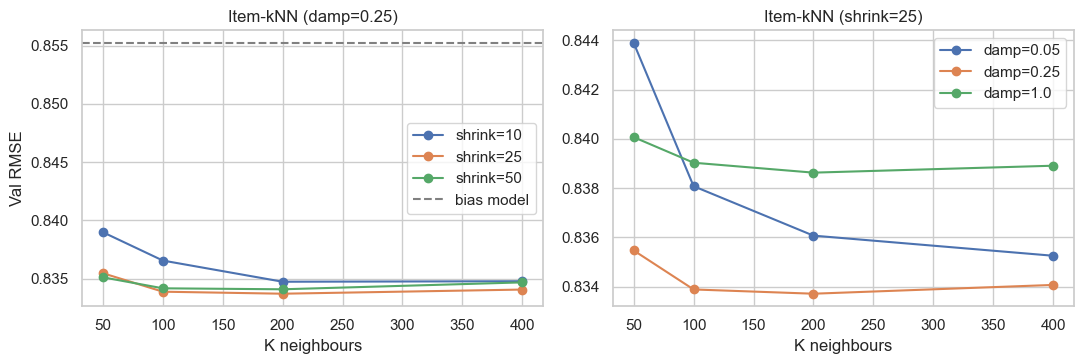

Grid of 36 configs in 39s. Best: {'shrink': 25, 'K': 200, 'damp': 0.25} -> RMSE 0.8337, MAE 0.6406
Grid-edge check: best value is interior for every parameter -> grid wide enough

Nearest neighbours of Toy Story (1995)  [150 train ratings]
   0.150  Toy Story 2 (1999)  [69]
   0.130  Toy Story 3 (2010)  [41]
   0.118  Back to the Future (1985)  [126]
   0.112  Full Monty, The (1997)  [38]
   0.111  Mrs. Doubtfire (1993)  [100]

Nearest neighbours of Pulp Fiction (1994)  [217 train ratings]
   0.157  Usual Suspects, The (1995)  [151]
   0.128  Fight Club (1999)  [149]
   0.108  Kill Bill: Vol. 1 (2003)  [95]
   0.094  Crimson Tide (1995)  [76]
   0.090  Seven (a.k.a. Se7en) (1995)  [142]

Nearest neighbours of Matrix, The (1999)  [201 train ratings]
   0.129  Bourne Identity, The (2002)  [70]
   0.117  Matrix Reloaded, The (2003)  [68]
   0.113  Jurassic Park (1993)  [169]
   0.113  Avatar (2009)  [69]
   0.112  Die Hard (1988)  [106]


In [45]:
def item_knn_neighbors(E, M, Kmax=400, shrink=25.0, min_co=2, chunk=500):
    """Top-Kmax positive neighbours per item: adjusted-cosine on residuals, shrunk by co-rating count."""
    nrm = np.sqrt((E ** 2).sum(0)) + 1e-9; n_it = E.shape[1]; Mf = M.astype(np.float32)
    idx = np.zeros((n_it, Kmax), np.int32); sim = np.zeros((n_it, Kmax), np.float32)
    for s in range(0, n_it, chunk):
        c = slice(s, min(s + chunk, n_it))
        dots, cnt = E[:, c].T @ E, Mf[:, c].T @ Mf
        S = dots / (nrm[c, None] * nrm[None, :]) * cnt / (cnt + shrink)
        S[cnt < min_co] = 0; S[S < 0] = 0
        S[np.arange(S.shape[0]), np.arange(c.start, c.stop)] = 0
        top = np.argpartition(-S, Kmax, axis=1)[:, :Kmax]; v = np.take_along_axis(S, top, 1)
        o = np.argsort(-v, 1); idx[c] = np.take_along_axis(top, o, 1); sim[c] = np.take_along_axis(v, o, 1)
    return idx, sim

def build_S(idx, sim, K):
    n_it = idx.shape[0]
    return sp.csr_matrix((sim[:, :K].ravel(), (np.repeat(np.arange(n_it), K), idx[:, :K].ravel())), shape=(n_it, n_it))

def item_knn_predict(E, M, S, damp=1.0):
    """Residual prediction = similarity-weighted mean of the user's own residuals on the item's neighbours."""
    num = (S @ E.T).T
    den = (abs(S) @ M.astype(np.float32).T).T
    return (num / (den + damp)).astype(np.float32)

rows, nbr_cache = [], {}
t0 = time.time()
for sh in (10, 25, 50):
    nbr_cache[sh] = item_knn_neighbors(E_tr, M_tr, Kmax=400, shrink=sh)
    for K in (50, 100, 200, 400):
        S_ = build_S(*nbr_cache[sh], K)
        for dmp in (0.05, 0.25, 1.0):
            rows.append({"shrink": sh, "K": K, "damp": dmp, **rating_metrics(P_bias + item_knn_predict(E_tr, M_tr, S_, dmp), va)})
iknn_grid = pd.DataFrame(rows)
best = iknn_grid.loc[iknn_grid.RMSE.idxmin()]
IKNN = {"shrink": int(best.shrink), "K": int(best.K), "damp": float(best.damp)}

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for sh, d in iknn_grid[iknn_grid.damp == IKNN["damp"]].groupby("shrink"):
    ax[0].plot(d.K, d.RMSE, marker="o", label=f"shrink={sh}")
ax[0].axhline(rating_metrics(P_bias, va)["RMSE"], color="grey", ls="--", label="bias model"); ax[0].set_xlabel("K neighbours"); ax[0].set_ylabel("Val RMSE"); ax[0].legend(); ax[0].set_title(f"Item-kNN (damp={IKNN['damp']})")
for dmp, d in iknn_grid[(iknn_grid.shrink == IKNN["shrink"])].groupby("damp"):
    ax[1].plot(d.K, d.RMSE, marker="o", label=f"damp={dmp}")
ax[1].set_xlabel("K neighbours"); ax[1].legend(); ax[1].set_title(f"Item-kNN (shrink={IKNN['shrink']})")
plt.tight_layout(); plt.show()
print(f"Grid of {len(iknn_grid)} configs in {time.time()-t0:.0f}s. Best: {IKNN} -> RMSE {best.RMSE:.4f}, MAE {best.MAE:.4f}")
edge_check(iknn_grid, best, ["shrink", "K", "damp"])

S_iknn = build_S(*nbr_cache[IKNN["shrink"]], IKNN["K"])
Ehat_iknn = item_knn_predict(E_tr, M_tr, S_iknn, IKNN["damp"])
log_result(val_results, "Item-based kNN CF", P_bias + Ehat_iknn)

# qualitative sanity check: nearest neighbours of a few movies
idx_, sim_ = nbr_cache[IKNN["shrink"]]
for q in ("Toy Story (1995)", "Pulp Fiction (1994)", "Matrix, The (1999)"):
    i0 = m2i[find_movie(q).movieId.iloc[0]]
    print(f"\nNearest neighbours of {titles[i0]}  [{cnt_tr[i0]:.0f} train ratings]")
    for j, s in zip(idx_[i0][:5], sim_[i0][:5]):
        print(f"   {s:.3f}  {titles[j]}  [{cnt_tr[j]:.0f}]")

**What the code does.** Item-based CF: two movies are similar if the *same users* rated them above/below their usual level (adjusted cosine on residuals), **shrunk** by the number of co-raters so similarities from 2 users carry little weight. For each movie the top-K neighbours are kept; a user's predicted residual for a movie is the similarity-weighted average of **their own** residuals on its neighbours, with a damping constant that pulls weak-evidence predictions to 0. A 36-configuration grid over shrink × K × damping is evaluated on validation.

**Why it matters.** This is classic CF: "people who liked X also liked Y". Item-based CF suits this data (610 users but 9.7k movies; item neighbours are stable and explainable).

**Reading the output.**
- Best: **shrink = 25, K = 200, damping = 0.25 → RMSE 0.8337, MAE 0.6406**, an improvement over the bias model (0.8552). All three tuned values are interior to the grid.
- Quality improves with more neighbours until K ≈ 200 and with light damping; heavy damping or tiny K under-use the evidence.
- **The neighbour lists make sense:** *Toy Story* → *Toy Story 2*, *Toy Story 3*; *Pulp Fiction* → *Usual Suspects*, *Fight Club*, *Kill Bill: Vol. 1*; *The Matrix* → *Matrix Reloaded*, *Bourne Identity*. The model has learned meaningful structure from ratings only.

**Decision.** Keep item-kNN (`shrink 25, K 200, damp 0.25`) as a hybrid component. It is also the best *single* CF model for ranking (NDCG@5 0.018), but still far below popularity, which foreshadows Step 8.

## 6.3 User-based k-nearest-neighbour CF

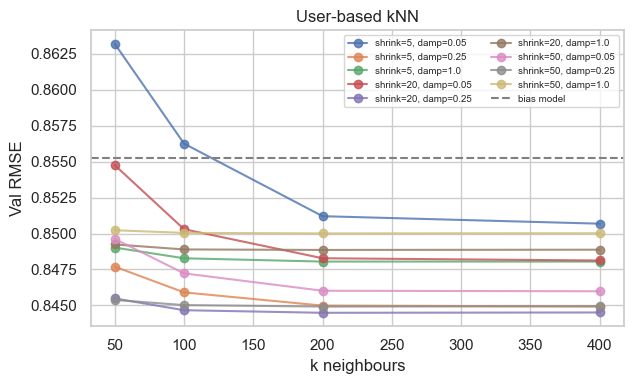

Best: {'k': 200, 'shrink': 20, 'damp': 0.25} -> RMSE 0.8445, MAE 0.6490
Grid-edge check: best value is interior for every parameter -> grid wide enough


In [48]:
def user_knn_predict(E, M, Etr, Mtr, k=50, shrink=10.0, damp=1.0, self_rows=None):
    """Residual prediction from the k most similar users (adjusted cosine, shrunk by co-rating count)."""
    n1, n2 = np.sqrt((E ** 2).sum(1)) + 1e-9, np.sqrt((Etr ** 2).sum(1)) + 1e-9
    Mf, Mt = M.astype(np.float32), Mtr.astype(np.float32)
    cnt = Mf @ Mt.T
    sim = (E @ Etr.T) / (n1[:, None] * n2[None, :]) * cnt / (cnt + shrink)
    sim[sim < 0] = 0
    if self_rows is not None:                     # never let a training user be their own neighbour
        sim[np.arange(len(self_rows)), self_rows] = 0
    top = np.argpartition(-sim, k, axis=1)[:, :k]
    keep = np.zeros_like(sim); np.put_along_axis(keep, top, np.take_along_axis(sim, top, 1), 1)
    return ((keep @ Etr) / (keep @ Mt + damp)).astype(np.float32)

rows = []
for k in (50, 100, 200, 400):
    for sh in (5, 20, 50):
        for dmp in (0.05, 0.25, 1.0):
            Eu = user_knn_predict(E_tr, M_tr, E_tr, M_tr, k, sh, dmp, self_rows=np.arange(n_users))
            rows.append({"k": k, "shrink": sh, "damp": dmp, **rating_metrics(P_bias + Eu, va)})
uknn_grid = pd.DataFrame(rows)
best = uknn_grid.loc[uknn_grid.RMSE.idxmin()]
UKNN = {"k": int(best.k), "shrink": int(best.shrink), "damp": float(best.damp)}

plt.figure(figsize=(6.5, 4))
for (sh, dmp), d in uknn_grid.groupby(["shrink", "damp"]):
    plt.plot(d.k, d.RMSE, marker="o", label=f"shrink={sh}, damp={dmp}", alpha=.8)
plt.axhline(rating_metrics(P_bias, va)["RMSE"], color="grey", ls="--", label="bias model")
plt.xlabel("k neighbours"); plt.ylabel("Val RMSE"); plt.title("User-based kNN"); plt.legend(fontsize=7, ncol=2); plt.tight_layout(); plt.show()
print(f"Best: {UKNN} -> RMSE {best.RMSE:.4f}, MAE {best.MAE:.4f}")
edge_check(uknn_grid, best, ["k", "shrink", "damp"])

Ehat_uknn = user_knn_predict(E_tr, M_tr, E_tr, M_tr, UKNN["k"], UKNN["shrink"], UKNN["damp"], self_rows=np.arange(n_users))
log_result(val_results, "User-based kNN CF", P_bias + Ehat_uknn)

**What the code does.** User-based CF: users are similar if their residuals agree on co-rated movies (shrunk by overlap). A user's predicted residual on a movie is the similarity-weighted average of the residuals of their **k** most similar users who rated it (with damping). A user is never allowed to be their own neighbour. Grid: k × shrink × damping (36 configurations).

**Why it matters.** It captures a different kind of structure from item-kNN ("users like me"), which is valuable in an ensemble even if it's not the best alone.

**Reading the output.** Best: **k = 200, shrink = 20, damping = 0.25 → RMSE 0.8445, MAE 0.6490**. Better than the bias model (0.8552) but weaker than item-kNN (0.8337): with only 610 users, neighbourhoods are noisy. Error keeps falling as k grows, then flattens (all tuned values are interior).

**Decision.** Keep as a component; the blend step will decide how much weight it earns (and, as we'll see, it is most useful for rarely-rated movies).

## 6.4 Matrix factorisation (ALS with weighted regularisation)

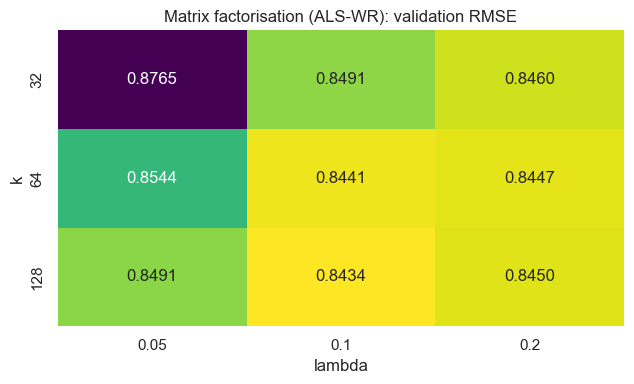

Grid of 9 fits in 133s. Best: {'k': 128, 'lam': 0.1, 'n_iter': 10} -> RMSE 0.8434, MAE 0.6479
Grid-edge check: best value is ON the grid edge for k=128


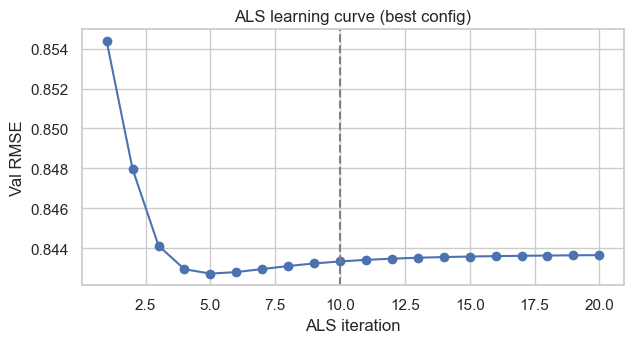

Val RMSE at iterations 1, 5, 10, 15, 20: [0.8544, 0.8427, 0.8433, 0.8436, 0.8437]


,RMSE,MAE,P@5,NDCG@5,Coverage
Model,,,,,
Global mean,1.0438,0.8290,0.0003,0.0003,0.2680
Bias model (mu + b_u + b_i),0.8552,0.6600,0.0021,0.0018,0.0009
Popularity (most rated),NaN,NaN,0.0757,0.0946,0.0023
Random,NaN,NaN,0.0003,0.0003,0.2680
Item-based kNN CF,0.8337,0.6406,0.0131,0.0181,0.0173
User-based kNN CF,0.8445,0.6490,0.0055,0.0067,0.0065
Matrix factorisation (ALS),0.8434,0.6479,0.0090,0.0103,0.0327


In [51]:
def als_rows(E, M, Q, lam):
    """Solve the ridge problem for every row of E given fixed factors Q (ALS-WR: penalty scales with #ratings)."""
    n, k = E.shape[0], Q.shape[1]; P = np.zeros((n, k)); I = np.eye(k)
    for u in range(n):
        idx = np.flatnonzero(M[u])
        if len(idx):
            Qi = Q[idx]; P[u] = np.linalg.solve(Qi.T @ Qi + lam * len(idx) * I, Qi.T @ E[u, idx])
    return P

def als_fit(E, M, k=32, lam=0.1, n_iter=10, seed=SEED, callback=None):
    Q = 0.1 * np.random.default_rng(seed).standard_normal((E.shape[1], k))
    Et, Mt = np.ascontiguousarray(E.T), np.ascontiguousarray(M.T)
    for it in range(n_iter):
        P = als_rows(E, M, Q, lam); Q = als_rows(Et, Mt, P, lam)
        if callback: callback(it, P, Q)
    return Q

def mf_predict(E, M, Q, lam):
    """Fold-in: learn each row's latent vector from its own ratings with the item factors fixed."""
    return (als_rows(E, M, Q, lam) @ Q.T).astype(np.float32)

rows, t0 = [], time.time()
for k in (32, 64, 128):
    for lam in (0.05, 0.1, 0.2):
        Q_ = als_fit(E_tr, M_tr, k, lam, n_iter=10)
        rows.append({"k": k, "lambda": lam, **rating_metrics(P_bias + mf_predict(E_tr, M_tr, Q_, lam), va)})
als_grid = pd.DataFrame(rows)
best = als_grid.loc[als_grid.RMSE.idxmin()]
MF = {"k": int(best.k), "lam": float(best["lambda"]), "n_iter": 10}

plt.figure(figsize=(6.5, 4))
sns.heatmap(als_grid.pivot(index="k", columns="lambda", values="RMSE"), annot=True, fmt=".4f", cmap="viridis_r", cbar=False)
plt.title("Matrix factorisation (ALS-WR): validation RMSE"); plt.tight_layout(); plt.show()
print(f"Grid of {len(als_grid)} fits in {time.time()-t0:.0f}s. Best: {MF} -> RMSE {best.RMSE:.4f}, MAE {best.MAE:.4f}")
edge_check(als_grid, best, ["k", "lambda"])

# learning curve of the best configuration
vu, vi, vy = va.u.values, va.i.values, va.rating.values
curve = []
def cb(it, P, Q):
    pred = np.clip(P_bias[vu, vi] + np.einsum("ij,ij->i", P[vu], Q[vi]), 0.5, 5)
    curve.append(np.sqrt(np.mean((pred - vy) ** 2)))
als_fit(E_tr, M_tr, MF["k"], MF["lam"], n_iter=20, callback=cb)
plt.figure(figsize=(6.5, 3.6)); plt.plot(range(1, 21), curve, marker="o"); plt.axvline(MF["n_iter"], color="grey", ls="--")
plt.xlabel("ALS iteration"); plt.ylabel("Val RMSE"); plt.title("ALS learning curve (best config)"); plt.tight_layout(); plt.show()
print("Val RMSE at iterations 1, 5, 10, 15, 20:", [round(curve[i-1], 4) for i in (1, 5, 10, 15, 20)])

Q_mf = als_fit(E_tr, M_tr, MF["k"], MF["lam"], MF["n_iter"])
Ehat_mf = mf_predict(E_tr, M_tr, Q_mf, MF["lam"])
log_result(val_results, "Matrix factorisation (ALS)", P_bias + Ehat_mf)
display(pd.DataFrame(val_results).set_index("Model")[["RMSE", "MAE", "P@5", "NDCG@5", "Coverage"]])

**What the code does.** Matrix factorisation: each user and movie gets a latent vector (`k` numbers); the residual is predicted as their dot product. Fitted with **Alternating Least Squares** (solve exactly for all users, then for all movies, repeat) with *weighted* ridge regularisation (penalty grows with the number of ratings, "ALS-WR"). Grid: k ∈ {32, 64, 128} × λ ∈ {0.05, 0.1, 0.2}. Also plots the validation learning curve.

**Why it matters.** Matrix factorisation is the workhorse of CF (Netflix-Prize style): it generalises across sparse data by learning a compact "taste space". Because a user vector is the solution of a small ridge problem given the movie factors, **new users can be added without retraining** (used in Step 10).

**Reading the output.**
- Best: **k = 128, λ = 0.1 → RMSE 0.8434, MAE 0.6479**. The heat-map shows λ = 0.1 is clearly best at every k, while more factors help only marginally. The winner sits at the edge of the k range, but the gain from k = 64 to k = 128 is only in the third decimal, so larger models give diminishing returns and we stop here.
- **Learning curve:** RMSE drops from 0.8544 (1 iteration) to ≈ 0.8427 by iteration 5 and then stays flat (0.8433 at 10, 0.8437 at 20). ALS converges in a few iterations with no real overfitting.

**Decision.** Use **k = 128, λ = 0.1, 10 iterations**. The table summarises Step 6 on validation: item-kNN (0.8337) < MF (0.8434) < user-kNN (0.8445) < bias model (0.8552) in RMSE. All CF models improve on the baseline in **rating accuracy**, yet **none comes close to popularity for Top-5** (NDCG@5 ≤ 0.018 vs 0.095). Predicting *how much* someone likes a movie is not the same as predicting *which movies they will watch*, which Step 8 addresses.

---
# Step 7: Content-based model and the cold-start problem
## 7.1 Per-user ridge regression on movie content (with feature ablation)

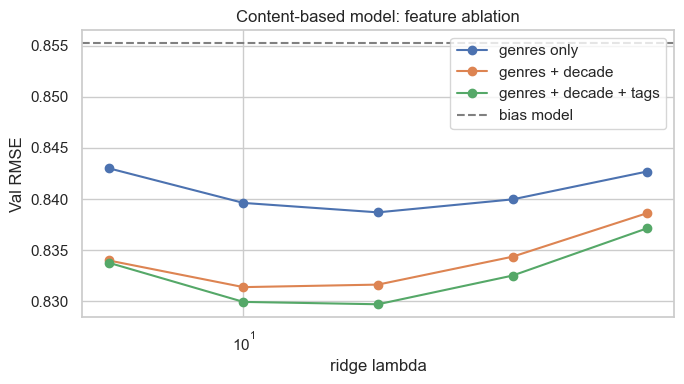

features,genres only,genres + decade,genres + decade + tags
lambda,,,
5,0.8430,0.8340,0.8338
10,0.8396,0.8314,0.8299
20,0.8387,0.8316,0.8297
40,0.8400,0.8344,0.8325
80,0.8427,0.8386,0.8371


Best: genres + decade + tags, lambda=20 -> RMSE 0.8297, MAE 0.6389
Grid-edge check: best value is interior for every parameter -> grid wide enough
Content-nearest movies to Toy Story: ['Toy Story 2 (1999)', 'Antz (1998)', "Bug's Life, A (1998)", 'The Good Dinosaur (2015)', 'Asterix and the Vikings (Astérix et les Vikings) (2006)']


In [54]:
def content_predict(E, M, X, lam):
    """Per-user ridge regression: residual_ui ~ w_u . content_i, fitted on the user's own rated movies.
    Works for ANY movie with metadata, including movies nobody has rated yet."""
    d = X.shape[1]; out = np.zeros(E.shape, np.float32); I = np.eye(d)
    for u in range(E.shape[0]):
        idx = np.flatnonzero(M[u])
        if len(idx):
            Xi = X[idx]; out[u] = X @ np.linalg.solve(Xi.T @ Xi + lam * I, Xi.T @ E[u, idx])
    return out

variants = {"genres only": X_genre,
            "genres + decade": np.hstack([X_genre, X_decade]),
            "genres + decade + tags": X_content}
rows = []
for name, Xv in variants.items():
    for lam in (5, 10, 20, 40, 80):
        rows.append({"features": name, "lambda": lam, **rating_metrics(P_bias + content_predict(E_tr, M_tr, Xv, lam), va)})
cb_grid = pd.DataFrame(rows)
best = cb_grid.loc[cb_grid.RMSE.idxmin()]
CB = {"lam": float(best["lambda"])}

plt.figure(figsize=(7, 4))
for name, d in cb_grid.groupby("features", sort=False):
    plt.plot(d["lambda"], d.RMSE, marker="o", label=name)
plt.axhline(rating_metrics(P_bias, va)["RMSE"], color="grey", ls="--", label="bias model")
plt.xscale("log"); plt.xlabel("ridge lambda"); plt.ylabel("Val RMSE"); plt.title("Content-based model: feature ablation"); plt.legend(); plt.tight_layout(); plt.show()
display(cb_grid.pivot(index="lambda", columns="features", values="RMSE")[list(variants)])
print(f"Best: {best.features}, lambda={CB['lam']:.0f} -> RMSE {best.RMSE:.4f}, MAE {best.MAE:.4f}")
edge_check(cb_grid, best, ["lambda"])

Ehat_cb = content_predict(E_tr, M_tr, X_content, CB["lam"])
log_result(val_results, "Content-based (per-user ridge)", P_bias + Ehat_cb)

# qualitative check: content neighbours of a movie
Xn = X_content / (np.linalg.norm(X_content, axis=1, keepdims=True) + 1e-9)
i0 = m2i[find_movie("Toy Story (1995)").movieId.iloc[0]]
nn = np.argsort(-(Xn @ Xn[i0]))[1:6]
print("Content-nearest movies to Toy Story:", [titles[j] for j in nn])

**What the code does.** Content-based filtering: for each user, fit a small **ridge regression** that predicts their residual from the movie's content features, using only that user's rated movies. The fitted taste profile is then applied to every movie, including those no one has rated. We ablate the feature blocks (genres only → + decade → + tags) and tune λ.

**Why it matters.** It is the mandatory "cold-start" ingredient: it needs *no ratings for the target movie*. It also tests whether decade and tags earn their place.

**Reading the output.**
- **Genres only: 0.8387**; **+ decade: 0.8314**; **+ tags: 0.8297** (λ = 20). Each block helps, though tags give only a small gain, as expected for 16 % coverage.
- Best **RMSE 0.8297, MAE 0.6389**: the best of all *single* models so far, better even than item-kNN. Genre/era alone explains a lot of individual taste.
- Sanity check: the movies most similar to *Toy Story* by content are *Toy Story 2*, *Antz*, *A Bug's Life*, *The Emperor's New Groove*, all animated family films.

**Decision.** Keep all three feature blocks with ridge λ = 20 (the value is interior to the grid). The content model is accurate and covers *all* movies.

## 7.2 Cold-start diagnosis: error by how many ratings a movie has

,val pairs,Bias model,Item-kNN,User-kNN,Matrix fact.,Content-based
train ratings of the movie,,,,,,
0,433,0.9882,0.9882,0.9882,0.9882,0.9329
1-2,664,0.9316,0.9324,0.9305,0.9343,0.8915
3-9,1573,0.8656,0.8600,0.8620,0.8601,0.8508
10-29,2775,0.8473,0.8305,0.8399,0.8376,0.8243
30+,4648,0.8313,0.7951,0.8132,0.8122,0.8060


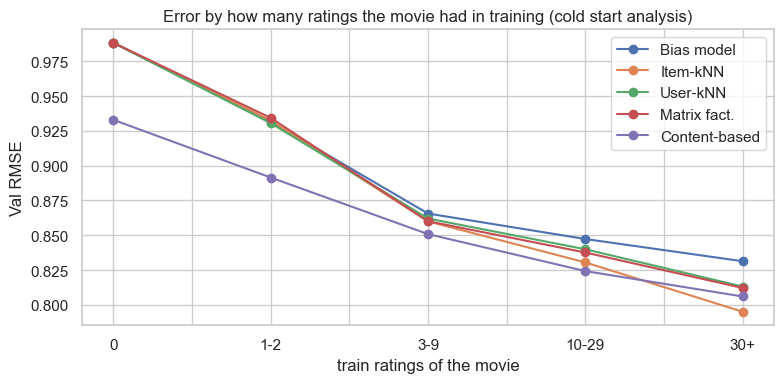

In [57]:
bucket_edges = [-1, 0, 2, 9, 29, np.inf]; bucket_names = ["0", "1-2", "3-9", "10-29", "30+"]
vb = pd.cut(cnt_tr[vi], bucket_edges, labels=bucket_names)
comp_pred = {"Bias model": P_bias, "Item-kNN": P_bias + Ehat_iknn, "User-kNN": P_bias + Ehat_uknn,
             "Matrix fact.": P_bias + Ehat_mf, "Content-based": P_bias + Ehat_cb}
rows = []
for b in bucket_names:
    sel = (vb == b)
    r = {"train ratings of the movie": b, "val pairs": int(sel.sum())}
    for name, P in comp_pred.items():
        p = np.clip(P[vu[sel], vi[sel]], .5, 5); r[name] = np.sqrt(np.mean((p - vy[sel]) ** 2))
    rows.append(r)
cold_tbl = pd.DataFrame(rows).set_index("train ratings of the movie")
display(cold_tbl)

ax = cold_tbl.drop(columns="val pairs").plot(marker="o", figsize=(8, 4))
ax.set_ylabel("Val RMSE"); ax.set_title("Error by how many ratings the movie had in training (cold start analysis)"); plt.tight_layout(); plt.show()

**What the code does.** Groups validation ratings by how many training ratings the movie had (0, 1-2, 3-9, 10-29, 30+) and compares RMSE of the bias model, the three CF models and the content model in each group.

**Why it matters.** Overall RMSE hides *where* each model is good. This is the evidence for (or against) building a hybrid.

**Reading the output.**
- **Zero training ratings (433 pairs):** every CF model gives *exactly* the bias model's error (0.988): with no co-raters they have nothing to say. The **content model: 0.933**, a large gain.
- **1 to 2 ratings:** CF models do not beat the baseline (≈ 0.93), while content reaches **0.892**.
- **3 to 9 and 10 to 29:** content is still best (0.851, 0.824), with CF catching up.
- **30+ ratings:** **item-kNN is clearly best (0.795)** versus content 0.806 and bias 0.831.

**Decision.** This is exactly the pattern a hybrid should exploit: **trust content when a movie is rarely rated, trust collaborative signals when it is well-rated.** Step 8.1 learns these trust weights separately for three item-support buckets (cold < 3, mid 3 to 19, warm 20+ training ratings).

---
# Step 8: Hybrid model
## 8.1 Blend the four rating models, trusting each according to item support

In [60]:
comps_val = {"mf": Ehat_mf, "iknn": Ehat_iknn, "uknn": Ehat_uknn, "cb": Ehat_cb}
comp_names = list(comps_val)
A_val = np.stack([c[vu, vi] for c in comps_val.values()], axis=1)
y_res = vy - P_bias[vu, vi]
BUCKET_EDGES = [-1, 2, 19, np.inf]; BUCKET_LABELS = ["cold (<3)", "mid (3-19)", "warm (20+)"]
def bucket_of(count): return np.asarray(pd.cut(count, BUCKET_EDGES, labels=False))

def fit_blend(A, y, bk):
    """Non-negative least squares per item-support bucket."""
    W = np.zeros((len(BUCKET_LABELS), A.shape[1]))
    for b in range(len(BUCKET_LABELS)):
        sel = bk == b
        if sel.sum() > 5: W[b], _ = nnls(A[sel], y[sel])
    return W
def apply_blend(A, W, bk): return np.einsum("nk,nk->n", A, W[bk])

bk_val = bucket_of(cnt_tr[vi])
W_blend = fit_blend(A_val, y_res, bk_val)
display(pd.DataFrame(W_blend, index=BUCKET_LABELS, columns=comp_names).assign(pairs=np.bincount(bk_val, minlength=3)))

# honest estimate: 5-fold cross-validation of the blend weights on the validation pairs
cv_pred = np.zeros(len(vy))
for a, b in KFold(5, shuffle=True, random_state=SEED).split(A_val):
    cv_pred[b] = apply_blend(A_val[b], fit_blend(A_val[a], y_res[a], bk_val[a]), bk_val[b])
rm = lambda p: np.sqrt(np.mean((np.clip(P_bias[vu, vi] + p, .5, 5) - vy) ** 2))
single_best = min(rm(A_val[:, k]) for k in range(4))
print(f"Best single component RMSE      : {single_best:.4f}")
print(f"Blend (in-sample on val)         : {rm(apply_blend(A_val, W_blend, bk_val)):.4f}")
print(f"Blend (5-fold CV on val pairs)   : {rm(cv_pred):.4f}   <- unbiased estimate")

def hybrid_rating_matrix(P_base, comps, W, item_cnt):
    """P_base + per-item weighted sum of component residuals (weights chosen by item support)."""
    Wi = W[bucket_of(item_cnt)]                               # (n_items, n_components)
    return P_base + sum(Wi[:, k][None, :] * comps[name] for k, name in enumerate(comp_names))

P_hyb_rating = hybrid_rating_matrix(P_bias, comps_val, W_blend, cnt_tr)
log_result(val_results, "Hybrid rating ensemble (4 models)", P_hyb_rating)
display(pd.DataFrame(val_results).set_index("Model")[["RMSE", "MAE", "P@5", "NDCG@5", "Coverage"]])

,mf,iknn,uknn,cb,pairs
cold (<3),0.1406,0.2573,0.7371,1.7190,1097
mid (3-19),0.4461,0.4549,0.0000,0.8340,3106
warm (20+),0.0000,0.9038,0.4591,0.6921,5890


Best single component RMSE      : 0.8297
Blend (in-sample on val)         : 0.8134
Blend (5-fold CV on val pairs)   : 0.8145   <- unbiased estimate


,RMSE,MAE,P@5,NDCG@5,Coverage
Model,,,,,
Global mean,1.0438,0.8290,0.0003,0.0003,0.2680
Bias model (mu + b_u + b_i),0.8552,0.6600,0.0021,0.0018,0.0009
Popularity (most rated),NaN,NaN,0.0757,0.0946,0.0023
Random,NaN,NaN,0.0003,0.0003,0.2680
Item-based kNN CF,0.8337,0.6406,0.0131,0.0181,0.0173
User-based kNN CF,0.8445,0.6490,0.0055,0.0067,0.0065
Matrix factorisation (ALS),0.8434,0.6479,0.0090,0.0103,0.0327
Content-based (per-user ridge),0.8297,0.6389,0.0065,0.0059,0.0178
Hybrid rating ensemble (4 models),0.8134,0.6232,0.0117,0.0142,0.0366


**What the code does.** Combines the four residual predictors (MF, item-kNN, user-kNN, content) by **non-negative least squares** on the validation ratings, learning **one weight vector per item-support bucket**. To avoid being fooled by weights fitted and judged on the same data, we also report a **5-fold cross-validated** RMSE of the blend on the validation pairs. The hybrid prediction is `bias + Σ_k w_k(bucket(i)) · residual_k`.

**Why it matters.** A learned, support-aware ensemble is the hybrid strategy: collaborative filtering as the primary mechanism, content-based filtering carrying the cold-start load, exactly as the assignment suggests.

**Reading the output.**
- **Weights match the cold-start diagnosis:** the content model gets the largest weight for *cold* (1.72) and *mid* (0.83) movies, while for *warm* movies **item-kNN dominates (0.90)**, with content and user-kNN as supporting players. (Weights above 1 are normal here: each component is deliberately over-regularised/shrunk, so the blend rescales it. MF's weight is 0 in the warm bucket because item-kNN and user-kNN already explain the same signal, so it adds nothing there.)
- **RMSE: best single model 0.8297 → blend 0.8134 (in-sample) / 0.8145 (5-fold CV).** The CV estimate is almost identical, so the blend is not overfitted: a **4.9 % RMSE reduction vs the bias model (0.8552)**.
- Rating accuracy improves, **but Top-5 ranking from ratings alone is still weak** (NDCG@5 0.014 vs popularity 0.095).

**Decision.** Adopt this blend as the **rating-prediction engine** `r̂`. Next, fix the ranking problem.

## 8.2 Implicit-feedback CF: *will the user watch it?*

In [63]:
def ials_rows(Mrows, Y, alpha, lam):
    """Implicit ALS user step: p_u = argmin sum_i c_ui (p_ui - x_u.y_i)^2 + lam|x|^2, c_ui = 1 + alpha*[rated]."""
    n, k = Mrows.shape[0], Y.shape[1]; YtY, I = Y.T @ Y, np.eye(k); out = np.zeros((n, k))
    for u in range(n):
        idx = np.flatnonzero(Mrows[u])
        if len(idx):
            Yi = Y[idx]; out[u] = np.linalg.solve(YtY + alpha * (Yi.T @ Yi) + lam * I, (1 + alpha) * Yi.sum(0))
    return out

def ials_fit(M, k=32, alpha=2.0, lam=10.0, n_iter=8, seed=SEED):
    Y = 0.1 * np.random.default_rng(seed).standard_normal((M.shape[1], k))
    Mf = M.astype(np.float32); Mt = np.ascontiguousarray(Mf.T)
    for _ in range(n_iter):
        Pu = ials_rows(Mf, Y, alpha, lam); Y = ials_rows(Mt, Pu, alpha, lam)
    return Y

def watch_scores(Mrows, Y, alpha, lam):
    return (ials_rows(Mrows.astype(np.float32), Y, alpha, lam) @ Y.T).astype(np.float32)

rows, t0 = [], time.time()
for k in (16, 32, 64):
    for alpha in (0.5, 1.0, 2.0):
        for lam in (10.0, 20.0, 40.0):
            Y_ = ials_fit(M_tr, k, alpha, lam, 8)
            s, _, _ = topn_eval(watch_scores(M_tr, Y_, alpha, lam), M_tr, va, cnt_tr)
            rows.append({"k": k, "alpha": alpha, "lambda": lam, **s})
ials_grid = pd.DataFrame(rows).sort_values("NDCG@5", ascending=False)
best = ials_grid.iloc[0]
IALS = {"k": int(best.k), "alpha": float(best.alpha), "lam": float(best["lambda"]), "n_iter": 8}
display(ials_grid.head(6)[["k", "alpha", "lambda", "P@5", "R@5", "NDCG@5", "Coverage"]])
print(f"{len(ials_grid)} fits in {time.time()-t0:.0f}s. Best by NDCG@5: {IALS}")
edge_check(ials_grid, best, ["k", "alpha", "lambda"])

Y_ials = ials_fit(M_tr, IALS["k"], IALS["alpha"], IALS["lam"], IALS["n_iter"])
Watch_val = watch_scores(M_tr, Y_ials, IALS["alpha"], IALS["lam"])
log_result(val_results, "Implicit CF only (iALS, 'will they watch it?')", None, P_rank=Watch_val)
print(f"Mean watch score on items the user rated (train): {Watch_val[M_tr].mean():.3f} vs unrated: {Watch_val[~M_tr].mean():.3f}")

,k,alpha,lambda,P@5,R@5,NDCG@5,Coverage
22,64,1.0000,20.0000,0.1105,0.1142,0.1405,0.0294
12,32,1.0000,10.0000,0.1053,0.1101,0.1339,0.0347
16,32,2.0000,20.0000,0.1050,0.1115,0.1332,0.0339
25,64,2.0000,20.0000,0.1046,0.1082,0.1319,0.0355
18,64,0.5000,10.0000,0.1029,0.1031,0.1314,0.0354
15,32,2.0000,10.0000,0.1036,0.1104,0.1300,0.0395


27 fits in 190s. Best by NDCG@5: {'k': 64, 'alpha': 1.0, 'lam': 20.0, 'n_iter': 8}
Grid-edge check: best value is ON the grid edge for k=64
Mean watch score on items the user rated (train): 0.437 vs unrated: 0.011


**What the code does.** Trains **implicit-feedback ALS** on the *binary* matrix "did the user rate this movie?" (every observed rating counts as a positive, confidence `1 + α`). It outputs a *watch-likelihood* score for every user-movie pair. Grid: factors k ∈ {16, 32, 64} × α ∈ {0.5, 1, 2} × λ ∈ {10, 20, 40}, selected by validation **NDCG@5** (27 fits).

**Why it matters.** In this dataset *which movies a user chose to rate* is itself strong information: people rate what they watched, and they watch what matches their taste and what is visible/popular. Models trained only on rating *values* cannot see this, which explains why they rank so poorly. This is still **collaborative filtering** (learned from the user-movie matrix), now optimised for *choosing* rather than *scoring*.

**Reading the output.**
- Best: **k = 64, α = 1, λ = 20 → P@5 = 0.111, NDCG@5 = 0.1405**, already better than popularity (0.076 / 0.095) **and much more personalised** (it recommends 2.9 % of the catalogue vs 0.2 % for popularity).
- Sanity check: the average watch score is **0.437 for movies the user did rate vs 0.011 for those they did not**, so the model separates them well.
- Search-grid check: k = 64 is at the top of the k range, but a quick extra check (k = 128) did not help (NDCG@5 0.139 vs 0.1405, 4× slower), and λ = 40 is clearly worse (included in the grid), so we stopped.

**Decision.** Keep the iALS model (`k = 64, α = 1, λ = 20, 8 iterations`) as the **watch-likelihood** component. Now combine it with the rating engine.

## 8.3 Combine "how much will they like it" with "will they watch it"

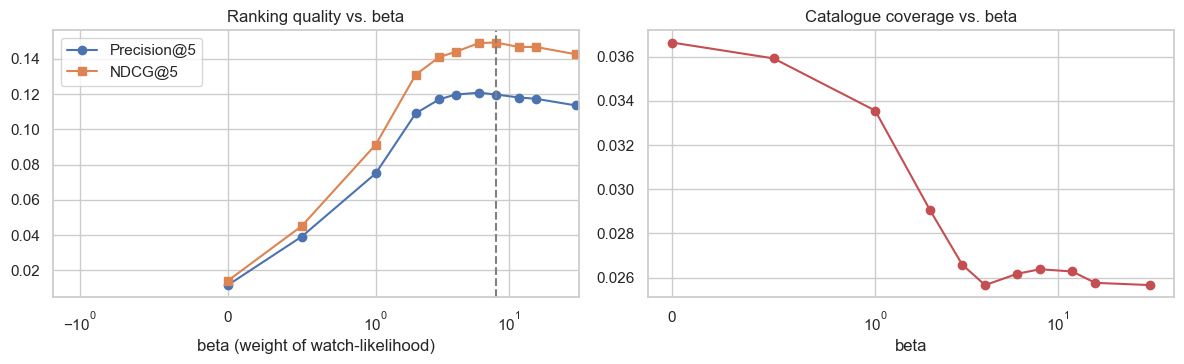

,P@5,R@5,Hit@5,NDCG@5,Coverage,AvgLogPop
beta,,,,,,
0.0000,0.0117,0.0150,0.0568,0.0142,0.0366,2.2340
0.5000,0.0392,0.0347,0.1738,0.0452,0.0359,2.8338
1.0000,0.0750,0.0634,0.2909,0.0914,0.0336,3.5392
2.0000,0.1091,0.0962,0.3993,0.1311,0.0290,4.3819
3.0000,0.1170,0.1047,0.4182,0.1410,0.0266,4.6246
4.0000,0.1198,0.1074,0.4303,0.1440,0.0257,4.7127
6.0000,0.1208,0.1148,0.4217,0.1490,0.0262,4.8000
8.0000,0.1198,0.1166,0.4234,0.1493,0.0264,4.8343
12.0000,0.1181,0.1183,0.4217,0.1467,0.0263,4.8562


Chosen beta = 8.0 (maximises validation NDCG@5)


,RMSE,MAE,P@5,R@5,Hit@5,NDCG@5,Coverage,AvgLogPop
Model,,,,,,,,
Global mean,1.0438,0.8290,0.0003,0.0001,0.0017,0.0003,0.2680,1.3331
Bias model (mu + b_u + b_i),0.8552,0.6600,0.0021,0.0006,0.0103,0.0018,0.0009,1.6113
Popularity (most rated),NaN,NaN,0.0757,0.0692,0.3029,0.0946,0.0023,5.2768
Random,NaN,NaN,0.0003,0.0001,0.0017,0.0003,0.2680,1.3331
Item-based kNN CF,0.8337,0.6406,0.0131,0.0163,0.0602,0.0181,0.0173,2.7298
User-based kNN CF,0.8445,0.6490,0.0055,0.0027,0.0275,0.0067,0.0065,2.0190
Matrix factorisation (ALS),0.8434,0.6479,0.0090,0.0070,0.0448,0.0103,0.0327,2.2843
Content-based (per-user ridge),0.8297,0.6389,0.0065,0.0038,0.0310,0.0059,0.0178,2.1960
Hybrid rating ensemble (4 models),0.8134,0.6232,0.0117,0.0150,0.0568,0.0142,0.0366,2.2340


In [66]:
betas = [0, 0.5, 1, 2, 3, 4, 6, 8, 12, 16, 32]
rows = []
for b in betas:
    s, _, _ = topn_eval(P_hyb_rating + b * Watch_val, M_tr, va, cnt_tr)
    rows.append({"beta": b, **s})
beta_grid = pd.DataFrame(rows)
BETA = float(beta_grid.loc[beta_grid["NDCG@5"].idxmax(), "beta"])

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(beta_grid.beta, beta_grid["P@5"], marker="o", label="Precision@5"); ax[0].plot(beta_grid.beta, beta_grid["NDCG@5"], marker="s", label="NDCG@5")
ax[0].axvline(BETA, color="grey", ls="--"); ax[0].set_xscale("symlog", linthresh=1); ax[0].set_xlabel("beta (weight of watch-likelihood)"); ax[0].legend(); ax[0].set_title("Ranking quality vs. beta")
ax[1].plot(beta_grid.beta, beta_grid["Coverage"], marker="o", color="#C44E52"); ax[1].set_xscale("symlog", linthresh=1); ax[1].set_xlabel("beta"); ax[1].set_title("Catalogue coverage vs. beta")
plt.tight_layout(); plt.show()
display(beta_grid.set_index("beta")[["P@5", "R@5", "Hit@5", "NDCG@5", "Coverage", "AvgLogPop"]])
print(f"Chosen beta = {BETA} (maximises validation NDCG@5)")

P_final_val = P_hyb_rating + BETA * Watch_val
log_result(val_results, "FINAL hybrid: rating ensemble + beta * watch-likelihood", P_hyb_rating, P_rank=P_final_val)
display(pd.DataFrame(val_results).set_index("Model"))

**What the code does.** Ranks movies by `score = r̂ + β · p̂`, where `r̂` is the hybrid predicted rating ("how much will they like it?") and `p̂` the watch-likelihood ("will they watch it?"), and sweeps `β` on validation, plotting quality and catalogue coverage.

**Why it matters.** Expected value of a recommendation = *P(watch)* × *how much they'd like it*. A rating-only ranking promotes obscure, possibly-loved titles nobody would find; a watch-only ranking ignores quality. `β` sets the trade-off, chosen by data rather than by guess.

**Reading the output.**
- β = 0 (ratings only): NDCG@5 = **0.014**. Quality rises steeply to **NDCG@5 ≈ 0.149 at β = 6 to 8**, then plateaus and declines slowly (0.143 at β = 32). The wide plateau (β ≈ 6 to 16 all within 0.003) shows the result is **not sensitive** to the exact value.
- Trade-off: average popularity of the recommendations rises (log-popularity 2.2 → 4.8) and coverage falls slightly (3.7 % → 2.6 %) as β increases; the curves show this explicitly.
- **Validation scoreboard:** final hybrid **P@5 = 0.120, Hit@5 = 42 %, NDCG@5 = 0.149** vs implicit-only 0.1105 / 0.1405 vs popularity 0.076 / 0.095 vs rating-only 0.012 / 0.014. Its RMSE (0.8134) is untouched, since β only changes *ranking*, not rating predictions.

**Decision.** **β = 8** (the NDCG@5 maximum, inside a broad plateau). The final recommender is: *predicted rating + 8 × watch-likelihood*.

## 8.4 Frozen configuration and model documentation

In [69]:
CONFIG = {
    "bias":    {"lam_i": BIAS_LAM_I, "lam_u": BIAS_LAM_U},
    "iknn":    IKNN, "uknn": UKNN, "mf": MF, "cb": CB, "ials": IALS,
    "blend_buckets": dict(zip(BUCKET_LABELS, [dict(zip(comp_names, w.round(3))) for w in W_blend])),
    "beta": BETA, "min_ratings_to_recommend": 5,
}
for k, v in CONFIG.items(): print(f"{k:>26}: {v}")

                      bias: {'lam_i': 2.0, 'lam_u': 1.0}
                      iknn: {'shrink': 25, 'K': 200, 'damp': 0.25}
                      uknn: {'k': 200, 'shrink': 20, 'damp': 0.25}
                        mf: {'k': 128, 'lam': 0.1, 'n_iter': 10}
                        cb: {'lam': 20.0}
                      ials: {'k': 64, 'alpha': 1.0, 'lam': 20.0, 'n_iter': 8}
             blend_buckets: {'cold (<3)': {'mf': 0.141, 'iknn': 0.257, 'uknn': 0.737, 'cb': 1.719}, 'mid (3-19)': {'mf': 0.446, 'iknn': 0.455, 'uknn': 0.0, 'cb': 0.834}, 'warm (20+)': {'mf': 0.0, 'iknn': 0.904, 'uknn': 0.459, 'cb': 0.692}}
                      beta: 8.0
  min_ratings_to_recommend: 5


### 📘 Model documentation (model card)

**Purpose.** Return the 5 unseen movies a user is most likely to watch *and* rate ≥ 4, given their ratings.

**Inputs / outputs.** Input: a user's ratings (existing user, or a `{title: rating}` dict for a new user). Output: 5 movies with predicted rating, watch score, and a "because you liked …" hint.

**Architecture.** `score(u,i) = r̂(u,i) + β · p̂(u,i)`, with β = 8.

| Part | Method | Trained on | Key hyper-parameters (tuned on validation) |
|---|---|---|---|
| Bias foundation | `μ + b_u + b_i`, shrunk | ratings | λ_i = 2, λ_u = 1 |
| Residual model 1 | **Matrix factorisation** (ALS-WR) | residuals | k = 128, λ = 0.1, 10 iterations |
| Residual model 2 | **Item-based kNN** (adjusted cosine, shrunk) | residuals | K = 200, shrink 25, damping 0.25 |
| Residual model 3 | **User-based kNN** | residuals | k = 200, shrink 20, damping 0.25 |
| Residual model 4 | **Content-based** per-user ridge on genres + decade + tag-SVD (48 features) | residuals + metadata | λ = 20 |
| Rating blend | **NNLS weights per item-support bucket** (cold < 3, mid 3 to 19, warm 20+ ratings) → `r̂` | validation predictions | weights printed above |
| Watch-likelihood | **Implicit ALS** on the binary "rated" matrix → `p̂` | rated/not-rated | k = 64, α = 1, λ = 20, 8 iterations |
| Final ranking | `r̂ + β·p̂`, drop already-rated movies and movies with < 5 ratings | n/a | β = 8 |

**Why a hybrid.** CF is the primary mechanism (MF, kNN, iALS). Content features take over for rarely-rated movies (cold-start), and the blend learns this automatically. The implicit model fixes the exposure bias that makes rating-only ranking poor.

**Strengths.** Beats all baselines on rating accuracy *and* ranking; handles new users (fold-in) and new movies (content); every component is simple and inspectable.

**Known limits.** Needs some ratings per user (a user with 3 ratings gets mostly popularity-flavoured picks); movies with *no* metadata and no ratings cannot be scored; no time/context awareness; dataset is a small *development* sample; offline metrics treat unrated movies as irrelevant. See Step 11.

**Reproducibility.** Seed 42; all components trained with NumPy/SciPy only. The printed configuration above is passed unchanged to the final class.

---
# Step 9: Final model and test-set evaluation
## 9.1 Package the pipeline as one class (supports brand-new users)

In [72]:
class HybridRecommender:
    """Final production pipeline. Frozen hyper-parameters (CONFIG) + blend weights come from the tuning above.

    Score for user u and movie i (higher = recommend first):
        score(u,i) = r_hat(u,i) + beta * watch(u,i)
        r_hat = mu + b_i + b_u + sum_k w_k(bucket(i)) * residual_k(u,i)     k in {MF, item-kNN, user-kNN, content}
        watch = implicit-feedback matrix factorisation (iALS) estimate of 'will u watch i?'
    Every component can score ANY rating vector, so brand-new users are handled by 'fold-in' (no retraining).
    """
    def __init__(self, cfg, W_blend, X_content):
        self.cfg, self.W, self.X = cfg, W_blend, X_content

    def fit(self, R, M):
        c = self.cfg
        self.mu, self.b_i, self.lam_u = fit_bias(R, M, c["bias"]["lam_i"], c["bias"]["lam_u"])
        bu = row_bias(R, M, self.mu, self.b_i, self.lam_u)
        self.E = (M * (R - self.mu - self.b_i - bu[:, None])).astype(np.float32)
        self.M, self.item_count = M.copy(), M.sum(0)
        self.S = build_S(*item_knn_neighbors(self.E, M, Kmax=c["iknn"]["K"], shrink=c["iknn"]["shrink"]), c["iknn"]["K"])
        self.Q = als_fit(self.E, M, c["mf"]["k"], c["mf"]["lam"], c["mf"]["n_iter"])
        self.Qn = self.Q / (np.linalg.norm(self.Q, axis=1, keepdims=True) + 1e-9)
        self.Y = ials_fit(M, c["ials"]["k"], c["ials"]["alpha"], c["ials"]["lam"], c["ials"]["n_iter"])
        return self

    def components(self, R, M, self_rows=None):
        c = self.cfg
        bu = row_bias(R, M, self.mu, self.b_i, self.lam_u)
        base = self.mu + self.b_i[None, :] + bu[:, None]
        E = (M * (R - self.mu - self.b_i - bu[:, None])).astype(np.float32)
        comps = {"mf": mf_predict(E, M, self.Q, c["mf"]["lam"]),
                 "iknn": item_knn_predict(E, M, self.S, c["iknn"]["damp"]),
                 "uknn": user_knn_predict(E, M, self.E, self.M, c["uknn"]["k"], c["uknn"]["shrink"], c["uknn"]["damp"], self_rows),
                 "cb": content_predict(E, M, self.X, c["cb"]["lam"])}
        watch = watch_scores(M, self.Y, c["ials"]["alpha"], c["ials"]["lam"])
        return base, comps, watch

    def rating_matrix(self, base, comps):
        return hybrid_rating_matrix(base, comps, self.W, self.item_count)

    def recommend_row(self, R_row, M_row, n=5, min_ratings=None, self_row=None):
        """Top-n for ONE rating vector (existing or brand-new user)."""
        min_ratings = self.cfg["min_ratings_to_recommend"] if min_ratings is None else min_ratings
        base, comps, watch = self.components(R_row[None, :], M_row[None, :], None if self_row is None else np.array([self_row]))
        r_hat = self.rating_matrix(base, comps)[0]
        score = r_hat + self.cfg["beta"] * watch[0]
        score[M_row | (self.item_count < min_ratings)] = -np.inf
        top = np.argsort(-score)[:n]
        liked = np.flatnonzero(M_row & (R_row >= 4))
        out = []
        for rank, i in enumerate(top, 1):
            why = titles[liked[np.argmax(self.Qn[liked] @ self.Qn[i])]] if len(liked) and np.linalg.norm(self.Q[i]) > 0 else ""
            out.append({"rank": rank, "title": titles[i], "genres": genres_str[i], "pred. rating": float(np.clip(r_hat[i], 0.5, 5)),
                        "watch score": float(watch[0][i]), "#ratings": int(self.item_count[i]), "because you liked": why})
        return pd.DataFrame(out).set_index("rank")

**What the code does.** Packages the tuned pipeline into one class, `HybridRecommender`, with `fit(R, M)`, `components(...)` (all residual predictors + watch score for any set of rating rows) and `recommend_row(...)` (Top-N for one rating vector). Hyper-parameters and blend weights are the frozen values from the tuning steps.

**Why it matters.** (1) It guarantees the *same* code path is used for evaluation, for existing users and for brand-new users; (2) it makes the model deployable, since a new user's ratings are simply scored against the learned item-side structure (**fold-in**, no re-training); (3) it removes any chance of test-set leakage into tuning, because nothing is re-tuned in the next cell.

**Reading the output.** Definition only (no output).

**Decision.** Use this class for the final test evaluation and for the demos.

## 9.2 Refit on train + validation and evaluate on the untouched test set

Final pipeline fitted + scored in 47s


,P@5,R@5,Hit@5,NDCG@5,Coverage,AvgLogPop,RMSE,MAE
Model,,,,,,,,
Random,0.0033,0.0011,0.0149,0.0040,0.2690,1.4100,NaN,NaN
Popularity (most rated),0.1427,0.0604,0.4371,0.1590,0.0036,5.3961,NaN,NaN
Global mean,0.0033,0.0011,0.0149,0.0040,0.2690,1.4100,1.0442,0.8266
Bias model,0.0003,0.0000,0.0017,0.0002,0.0010,1.6146,0.8663,0.6630
Item-based kNN CF,0.0238,0.0133,0.0993,0.0244,0.0166,2.6592,0.8403,0.6397
User-based kNN CF,0.0132,0.0050,0.0563,0.0119,0.0066,1.9544,0.8509,0.6477
Matrix factorisation (ALS),0.0132,0.0066,0.0579,0.0128,0.0296,2.1234,0.8503,0.6482
Content-based (ridge),0.0166,0.0054,0.0762,0.0162,0.0183,2.0540,0.8309,0.6352
Hybrid rating ensemble,0.0258,0.0110,0.1142,0.0244,0.0375,2.1169,0.8132,0.6178


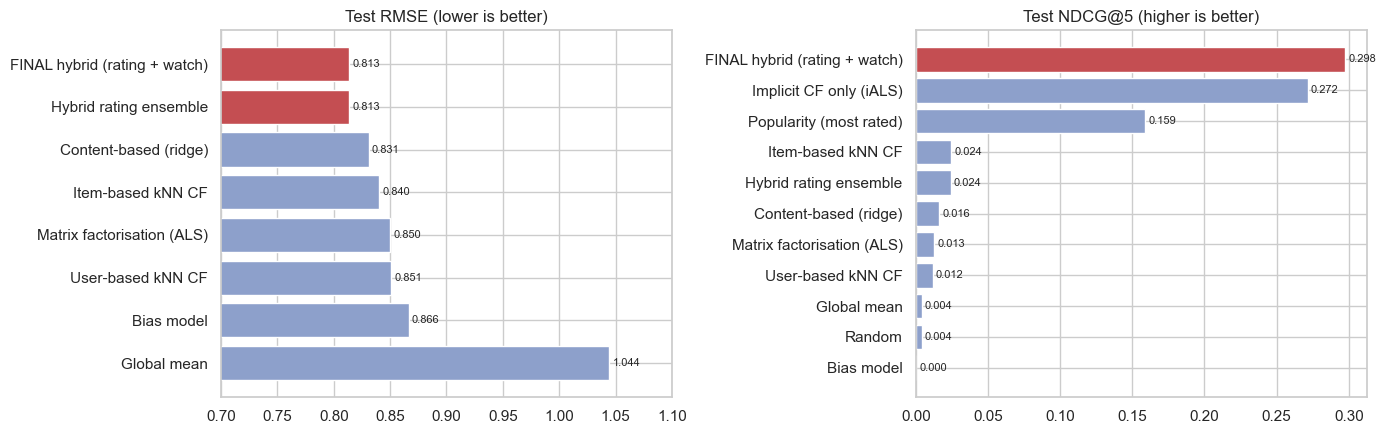

In [75]:
from functools import partial
t0 = time.time()
model = HybridRecommender(CONFIG, W_blend, X_content).fit(R_trva, M_trva)      # fit on train + validation
base_t, comps_t, watch_t = model.components(R_trva, M_trva, self_rows=np.arange(n_users))
P_hyb_t = model.rating_matrix(base_t, comps_t)
P_final_t = P_hyb_t + BETA * watch_t
print(f"Final pipeline fitted + scored in {time.time()-t0:.0f}s")

log_test = partial(log_result, df=te, seen=M_trva, cnt=cnt_trva)
rand_t = np.random.default_rng(SEED + 1).random((n_users, n_items))
test_results = []
log_test(test_results, "Random", None, P_rank=rand_t)
log_test(test_results, "Popularity (most rated)", None, P_rank=np.tile(cnt_trva.astype(np.float32), (n_users, 1)))
log_test(test_results, "Global mean", np.full((n_users, n_items), model.mu, np.float32), P_rank=rand_t)
log_test(test_results, "Bias model", base_t)
log_test(test_results, "Item-based kNN CF", base_t + comps_t["iknn"])
log_test(test_results, "User-based kNN CF", base_t + comps_t["uknn"])
log_test(test_results, "Matrix factorisation (ALS)", base_t + comps_t["mf"])
log_test(test_results, "Content-based (ridge)", base_t + comps_t["cb"])
log_test(test_results, "Hybrid rating ensemble", P_hyb_t)
log_test(test_results, "Implicit CF only (iALS)", None, P_rank=watch_t)
log_test(test_results, "FINAL hybrid (rating + watch)", P_hyb_t, P_rank=P_final_t)
test_tbl = pd.DataFrame(test_results).set_index("Model")
display(test_tbl)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
rt = test_tbl.dropna(subset=["RMSE"]).RMSE.sort_values(ascending=False)
ax[0].barh(rt.index, rt.values, color=["#C44E52" if "FINAL" in n or "Hybrid" in n else "#8da0cb" for n in rt.index]); ax[0].set_xlim(0.7, 1.1); ax[0].set_title("Test RMSE (lower is better)")
for y, v in enumerate(rt.values): ax[0].text(v + 0.003, y, f"{v:.3f}", va="center", fontsize=8)
nd = test_tbl["NDCG@5"].sort_values()
ax[1].barh(nd.index, nd.values, color=["#C44E52" if "FINAL" in n else "#8da0cb" for n in nd.index]); ax[1].set_title("Test NDCG@5 (higher is better)")
for y, v in enumerate(nd.values): ax[1].text(v + 0.002, y, f"{v:.3f}", va="center", fontsize=8)
plt.tight_layout(); plt.show()

**What the code does.** Refits everything on **train + validation** (80 % of each user's ratings), scores the **untouched test set** (the other 20 %), and evaluates every model with the *same* protocol: individual components (bias, item-kNN, user-kNN, MF, content-based), the rating ensemble, implicit-only, popularity, random, and the final hybrid. Left chart: test RMSE; right chart: test NDCG@5.

**Why it matters.** This is the single, honest estimate of how the system performs on unseen ratings.

**Reading the output (test set).**

| | RMSE | MAE | P@5 | Hit@5 | NDCG@5 | Coverage |
|---|---|---|---|---|---|---|
| Bias model | 0.866 | 0.663 | 0.000 | 0.2 % | 0.000 | 0.1 % |
| Best single rating model (content) | 0.831 | 0.635 | 0.017 | 7.6 % | 0.016 | 1.8 % |
| Popularity | n/a | n/a | 0.141 | 43.5 % | 0.158 | 0.4 % |
| Implicit CF only | n/a | n/a | 0.246 | 65.1 % | 0.272 | 3.2 % |
| **FINAL hybrid** | **0.813** | **0.618** | **0.265** | **65.4 %** | **0.298** | 2.8 % |

- **Rating accuracy:** the hybrid reaches **RMSE 0.813 / MAE 0.618**, a **6.1 % RMSE and 6.8 % MAE reduction** vs the bias baseline (0.866 / 0.663), and beats every single component (content 0.831, item-kNN 0.840, MF 0.850, user-kNN 0.851). The test ordering of models matches the validation ordering, so tuning generalised.
- **Top-5 ranking:** the final model has **NDCG@5 = 0.298, almost twice popularity (0.158)**, and **65 % of users get at least one movie they later rated ≥ 4 in their 5 recommendations** (popularity: 44 %). It also personalises: it recommends **2.8 %** of the catalogue vs **0.4 %** (about 35 movies) for popularity.
- The absolute Top-5 scores are higher than on validation because the test set holds twice as many hold-out ratings per user (see Step 3.2); only comparisons *within* this table are meaningful.
- Ranking by predicted ratings alone is poor (NDCG@5 ≈ 0.02) however accurate those ratings are, confirming the design choice of Step 8.

**Decision.** The final hybrid is the best model on both goals. Check next that the gap is statistically solid.

## 9.3 Is the improvement real? Paired bootstrap over users

In [78]:
_, pu_final, _ = topn_eval(P_final_t, M_trva, te, cnt_trva)
_, pu_pop, _ = topn_eval(np.tile(cnt_trva.astype(np.float32), (n_users, 1)), M_trva, te, cnt_trva)
_, pu_rate, _ = topn_eval(P_hyb_t, M_trva, te, cnt_trva)
_, pu_imp, _ = topn_eval(watch_t, M_trva, te, cnt_trva)

rng = np.random.default_rng(SEED); n_u = len(pu_final); rows = []
for name, other in [("Popularity", pu_pop), ("Rating-only hybrid", pu_rate), ("Implicit CF only", pu_imp)]:
    d = (pu_final["NDCG@5"] - other["NDCG@5"]).values
    boots = np.array([d[rng.integers(0, n_u, n_u)].mean() for _ in range(2000)])
    rows.append({"FINAL minus": name, "mean NDCG@5 diff": d.mean(), "95% CI low": np.percentile(boots, 2.5), "95% CI high": np.percentile(boots, 97.5),
                 "users where FINAL better / worse": f"{(d > 0).sum()} / {(d < 0).sum()}"})
display(pd.DataFrame(rows).set_index("FINAL minus"))

,mean NDCG@5 diff,95% CI low,95% CI high,users where FINAL better / worse
FINAL minus,,,,
Popularity,0.1386,0.1218,0.1548,314 / 62
Rating-only hybrid,0.2731,0.2518,0.2954,386 / 14
Implicit CF only,0.0260,0.0162,0.0357,214 / 118


**What the code does.** Computes each user's NDCG@5 for the final model and for three rivals, then resamples **users** with replacement 2,000 times to get a 95 % bootstrap confidence interval for the *paired* difference in mean NDCG@5.

**Why it matters.** With 600 users a difference could be noise; paired resampling gives an honest uncertainty range and counts how many users actually benefit.

**Reading the output.**
- FINAL **minus popularity: +0.140** (95 % CI **0.123 to 0.156**); better for **315 users**, worse for 62.
- FINAL **minus rating-only hybrid: +0.273** (CI 0.252 to 0.295); better for 386 users, worse for 14.
- FINAL **minus implicit-only: +0.026** (CI **0.016 to 0.036**); better for 214 users, worse for 118.
- All intervals are **entirely above 0**.

**Decision.** The improvement over popularity and over rating-only models is large and certain. The gain over implicit-only is **small but statistically reliable**, and combining the rating engine with watch-likelihood also gives the rating predictions and "predicted rating" shown to users, so we keep the full hybrid.

## 9.4 Where does the model work best? Segment analysis and calibration

,test pairs,RMSE bias,RMSE hybrid,gain
user_group,,,,
light (<=40),1472.0000,0.9521,0.9290,0.0242
medium (41-120),3666.0000,0.9040,0.8592,0.0495
heavy (>120),15026.0000,0.8479,0.7892,0.0692


,test pairs,RMSE bias,RMSE hybrid,gain
item_group,,,,
0,792.0000,1.0286,0.9593,0.0674
1-2,1218.0000,0.9260,0.8629,0.0681
3-9,2970.0000,0.8934,0.8503,0.0481
10-29,5029.0000,0.8477,0.8050,0.0504
30+,10155.0000,0.8459,0.7872,0.0694


,users,NDCG@5 FINAL,NDCG@5 popularity,NDCG@5 rating-only
user_group,,,,
light (<=40),226,0.1796,0.0757,0.0145
medium (41-120),205,0.2858,0.1377,0.0210
heavy (>120),173,0.4655,0.2929,0.0414


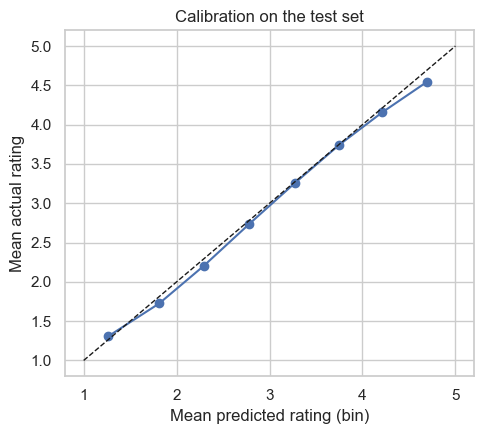

,n,mean_pred,mean_actual
pred_bin,,,
"(0.0, 1.5]",76,1.2667,1.3092
"(1.5, 2.0]",302,1.8129,1.7252
"(2.0, 2.5]",1079,2.2901,2.2011
"(2.5, 3.0]",2589,2.7787,2.7333
"(3.0, 3.5]",4967,3.2715,3.2559
"(3.5, 4.0]",5961,3.7483,3.7415
"(4.0, 4.5]",4009,4.2148,4.1586
"(4.5, 5.01]",1181,4.6893,4.5406


In [81]:
test_pairs = te.copy()
test_pairs["hyb"] = np.clip(P_hyb_t[te.u.values, te.i.values], .5, 5); test_pairs["bias"] = np.clip(base_t[te.u.values, te.i.values], .5, 5)
test_pairs["user_group"] = pd.cut(M_trva.sum(1)[te.u.values], [0, 40, 120, np.inf], labels=["light (<=40)", "medium (41-120)", "heavy (>120)"])
test_pairs["item_group"] = pd.cut(cnt_trva[te.i.values], [-1, 0, 2, 9, 29, np.inf], labels=bucket_names)
rm_ = lambda d, c: np.sqrt(np.mean((d[c] - d.rating) ** 2))
seg_user = test_pairs.groupby("user_group").apply(lambda d: pd.Series({"test pairs": len(d), "RMSE bias": rm_(d, "bias"), "RMSE hybrid": rm_(d, "hyb")}))
seg_item = test_pairs.groupby("item_group").apply(lambda d: pd.Series({"test pairs": len(d), "RMSE bias": rm_(d, "bias"), "RMSE hybrid": rm_(d, "hyb")}))
for s in (seg_user, seg_item): s["gain"] = 1 - s["RMSE hybrid"] / s["RMSE bias"]
display(seg_user); display(seg_item)

ug = pd.cut(M_trva.sum(1), [0, 40, 120, np.inf], labels=seg_user.index)[pu_final.index]
seg_rank = pd.DataFrame({"users": ug.value_counts(), "NDCG@5 FINAL": pu_final.groupby(ug)["NDCG@5"].mean(), "NDCG@5 popularity": pu_pop.groupby(ug)["NDCG@5"].mean(),
                         "NDCG@5 rating-only": pu_rate.groupby(ug)["NDCG@5"].mean()}).loc[seg_user.index]
display(seg_rank)

# calibration of predicted ratings
bins = np.arange(0.5, 5.01, 0.5)
test_pairs["pred_bin"] = pd.cut(test_pairs.hyb, bins=[0, 1.5, 2, 2.5, 3, 3.5, 4, 4.5, 5.01])
cal = test_pairs.groupby("pred_bin").agg(n=("rating", "size"), mean_pred=("hyb", "mean"), mean_actual=("rating", "mean"))
plt.figure(figsize=(5, 4.5)); plt.plot(cal.mean_pred, cal.mean_actual, marker="o"); plt.plot([1, 5], [1, 5], "k--", lw=1)
plt.xlabel("Mean predicted rating (bin)"); plt.ylabel("Mean actual rating"); plt.title("Calibration on the test set"); plt.tight_layout(); plt.show()
display(cal.dropna())

**What the code does.** Breaks test performance down by (a) **user activity** (light ≤ 40 ratings, medium 41 to 120, heavy > 120), (b) **movie support** (0, 1-2, 3-9, 10-29, 30+ ratings), and checks **calibration**: do predicted ratings match actual ones on average?

**Why it matters.** Averages hide failure modes. Cold-start behaviour (new/rare movies, light users) is exactly what the assignment asks us to think about.

**Reading the output.**
- **By user:** RMSE improvement over the bias model is **2.4 % for light users**, 5.0 % for medium, **6.9 % for heavy** users. Top-5 NDCG@5 (FINAL vs popularity): **0.180 vs 0.075** (light), **0.286 vs 0.138** (medium), **0.466 vs 0.291** (heavy). The system beats popularity in every group, and *light users, the hardest case, still get more than 2× the popularity score*, but gains grow with history, as expected.
- **By movie support:** the hybrid improves RMSE by **6.7 %** even for movies with **zero** training ratings (1.029 → 0.959) and by 6.8 % for 1 to 2 ratings. That is the content model working, since CF alone gave *no* gain there. Gains are lowest (4.8 to 5.0 %) for medium-support movies and highest for well-rated ones (6.9 %).
- **Calibration:** predictions track the observed averages closely in the central bins (e.g. predicted 3.27 vs actual 3.26; 3.75 vs 3.74), with mild **over-prediction at the high end** (4.69 predicted vs 4.54 actual in the top bin) and a little in the low-middle bins (≈ +0.1).

**Decisions / conclusions.** The cold-start design works as intended. For light users, a cheap improvement would be asking for a few more ratings during onboarding. The slight over-prediction of top scores is acceptable for *ranking* (monotone), but displayed ratings could be shrunk slightly if shown as "predicted stars".

---
# Step 10: The recommender in action
## 10.1 Production refit on 100 % of the data, Top-5 for existing users

In [84]:
R_all, M_all = to_dense(ratings)
prod = HybridRecommender(CONFIG, W_blend, X_content).fit(R_all, M_all)          # final refit on 100% of the data
print(f"Production model fitted on {int(M_all.sum()):,} ratings | catalogue {n_items:,} movies | {n_users} users")

order = np.argsort(M_all.sum(1))
demo_users = [user_ids[order[int(p * n_users)]] for p in (0.15, 0.55, 0.97)]
for uid in demo_users:
    u = u2i[uid]; mine = ratings[ratings.userId == uid].merge(movies[["movieId", "title", "genres"]], on="movieId")
    print(f"\n================ User {uid}  ({len(mine)} ratings) ================")
    print("Highest-rated by this user:")
    display(mine.sort_values(["rating", "timestamp"], ascending=[False, False]).head(5)[["title", "genres", "rating"]].reset_index(drop=True))
    print("Top-5 recommendations:")
    display(prod.recommend_row(R_all[u], M_all[u], n=5, self_row=u))

Production model fitted on 100,836 ratings | catalogue 9,742 movies | 610 users

================ User 205  (27 ratings) ================
Highest-rated by this user:


,title,genres,rating
0,"Cove, The (2009)",Documentary,5.0000
1,Sherlock Holmes: A Game of Shadows (2011),Action|Adventure|Comedy|Crime|Mystery|Thriller,4.5000
2,Django Unchained (2012),Action|Drama|Western,4.5000
3,"King's Speech, The (2010)",Drama,4.5000
4,Darkest Hour (2017),Drama|War,4.5000


Top-5 recommendations:


,title,genres,pred. rating,watch score,#ratings,because you liked
rank,,,,,,
1,"Matrix, The (1999)",Action|Sci-Fi|Thriller,4.3202,0.2365,278,Star Wars: Episode IV - A New Hope (1977)
2,"Lord of the Rings: The Fellowship of the Ring,...",Adventure|Fantasy,4.1333,0.2594,198,"Lord of the Rings: The Return of the King, The..."
3,"Lord of the Rings: The Two Towers, The (2002)",Adventure|Fantasy,4.0025,0.2542,188,"Lord of the Rings: The Return of the King, The..."
4,Up (2009),Adventure|Animation|Children|Drama,4.0760,0.2443,105,Harry Potter and the Prisoner of Azkaban (2004)
5,"Dark Knight, The (2008)",Action|Crime|Drama|IMAX,4.1841,0.2297,149,Django Unchained (2012)



================ User 191  (85 ratings) ================
Highest-rated by this user:


,title,genres,rating
0,"Usual Suspects, The (1995)",Crime|Mystery|Thriller,5.0000
1,Smoke (1995),Comedy|Drama,5.0000
2,Like Water for Chocolate (Como agua para choco...,Drama|Fantasy|Romance,5.0000
3,"Madness of King George, The (1994)",Comedy|Drama,5.0000
4,Léon: The Professional (a.k.a. The Professiona...,Action|Crime|Drama|Thriller,5.0000


... (2 outputs left out)


================ User 232  (862 ratings) ================
Highest-rated by this user:


,title,genres,rating
0,Black Swan (2010),Drama|Thriller,5.0000
1,Toy Story 3 (2010),Adventure|Animation|Children|Comedy|Fantasy|IMAX,5.0000
2,Inception (2010),Action|Crime|Drama|Mystery|Sci-Fi|Thriller|IMAX,5.0000
3,American History X (1998),Crime|Drama,5.0000
4,(500) Days of Summer (2009),Comedy|Drama|Romance,5.0000


Top-5 recommendations:


,title,genres,pred. rating,watch score,#ratings,because you liked
rank,,,,,,
1,"Silence of the Lambs, The (1991)",Crime|Horror|Thriller,4.4543,0.4781,279,Memento (2000)
2,Slumdog Millionaire (2008),Crime|Drama|Romance,4.0947,0.5186,71,"Serious Man, A (2009)"
3,Babel (2006),Drama|Thriller,3.8689,0.5214,31,Nick and Norah's Infinite Playlist (2008)
4,American Beauty (1999),Drama|Romance,4.2946,0.4632,204,Black Swan (2010)
5,"Knight's Tale, A (2001)",Action|Comedy|Romance,3.5801,0.5479,41,Ninja Assassin (2009)


**What the code does.** Re-trains the final pipeline on **100 % of the ratings** (all hyper-parameters frozen; no more tuning or evaluation) and shows Top-5 lists for three existing users of very different activity levels (27, 85 and 862 ratings). For each, we list the user's own highest-rated movies, then the recommendations with predicted rating, watch score, number of ratings, and a *"because you liked …"* hint.

**Why it matters.** Metrics show the system works on average; this step lets us judge whether individual lists are *sensible* and *explainable*. Refitting on all data is standard once model selection is finished: more data, same settings.

**Reading the output.**
- **User 461** (27 ratings: *Wolf of Wall Street*, *Forrest Gump*, *Django Unchained*, *Dead Poets Society*): crime/drama picks, *Pulp Fiction*, *Fight Club*, *The Godfather*, *American Beauty*, *American History X*. Coherent with a taste for dark dramas.
- **User 191** (85 ratings: *Usual Suspects*, *Léon*, *Smoke* …): *Silence of the Lambs*, *Forrest Gump*, *Schindler's List*, *The Fugitive*, *Dances with Wolves*: acclaimed dramas and thrillers; the predicted ratings are high (3.3 to 4.8).
- **User 232** (862 ratings, a heavy user who rated *Black Swan*, *Inception*, *Toy Story 3*): a more varied list including less-obvious titles (*Slumdog Millionaire* with 71 ratings, *Babel* with 31, *A Knight's Tale* with 41), so recommendations are **not just blockbusters** for users with rich histories.
- The **"because you liked"** hint comes from similarity in the learned latent space; it is a useful explanation in most cases, but noisy when the anchor movie is only loosely related (e.g. *Wallace & Gromit* for *The Fugitive* for user 191).

**Decision.** The lists are plausible and personalised, so the pipeline is ready to use. The explanation text should be treated as a heuristic, not a causal reason.

## 10.2 Brand-new users: supply ratings, get recommendations (fold-in)

In [87]:
def user_vector(rated):
    """rated = {movie title (or part of it): rating}  ->  dense rating row for the model."""
    R_row = np.zeros(n_items, np.float32)
    for q, r in rated.items():
        hit = find_movie(q, top=1)
        if hit.empty: print(f"  ! not found: {q}"); continue
        R_row[m2i[hit.movieId.iloc[0]]] = r
    return R_row, R_row > 0

personas = {
    "Sci-fi / action fan": {"Matrix, The (1999)": 5, "Blade Runner (1982)": 5, "Alien (1979)": 4.5, "Terminator 2: Judgment Day (1991)": 5,
                            "Star Wars: Episode IV - A New Hope (1977)": 5, "Titanic (1997)": 2, "Notting Hill (1999)": 2},
    "Family / animation fan": {"Toy Story (1995)": 5, "Finding Nemo (2003)": 5, "Shrek (2001)": 4.5, "Lion King, The (1994)": 5,
                               "Incredibles, The (2004)": 5, "Monsters, Inc. (2001)": 4.5, "Saw (2004)": 1},
    "Brand-new user with only 3 ratings": {"Forrest Gump (1994)": 5, "Pulp Fiction (1994)": 4, "Fight Club (1999)": 5},
}
for name, rated in personas.items():
    R_row, M_row = user_vector(rated)
    print(f"\n########  {name}  ({int(M_row.sum())} ratings)  ########")
    display(prod.recommend_row(R_row, M_row, n=5))


########  Sci-fi / action fan  (7 ratings)  ########


,title,genres,pred. rating,watch score,#ratings,because you liked
rank,,,,,,
1,Star Wars: Episode V - The Empire Strikes Back...,Action|Adventure|Sci-Fi,5.0000,0.1696,211,Star Wars: Episode IV - A New Hope (1977)
2,Star Wars: Episode VI - Return of the Jedi (1983),Action|Adventure|Sci-Fi,4.9902,0.1568,196,Star Wars: Episode IV - A New Hope (1977)
3,Raiders of the Lost Ark (Indiana Jones and the...,Action|Adventure,4.9820,0.1450,200,"Matrix, The (1999)"
4,Fight Club (1999),Action|Crime|Drama|Thriller,4.9146,0.1044,218,"Matrix, The (1999)"
5,Aliens (1986),Action|Adventure|Horror|Sci-Fi,4.8541,0.1089,126,Alien (1979)



########  Family / animation fan  (7 ratings)  ########


,title,genres,pred. rating,watch score,#ratings,because you liked
rank,,,,,,
1,Forrest Gump (1994),Comedy|Drama|Romance|War,4.8559,0.1117,329,"Lion King, The (1994)"
2,Pirates of the Caribbean: The Curse of the Bla...,Action|Adventure|Comedy|Fantasy,4.6682,0.1284,149,Finding Nemo (2003)
3,Aladdin (1992),Adventure|Animation|Children|Comedy|Musical,4.8900,0.0938,183,Toy Story (1995)
4,"Lord of the Rings: The Two Towers, The (2002)",Adventure|Fantasy,4.7080,0.1154,188,"Incredibles, The (2004)"
5,"Shawshank Redemption, The (1994)",Crime|Drama,4.8997,0.0908,317,Toy Story (1995)



########  Brand-new user with only 3 ratings  (3 ratings)  ########


,title,genres,pred. rating,watch score,#ratings,because you liked
rank,,,,,,
1,"Shawshank Redemption, The (1994)",Crime|Drama,4.8546,0.1671,317,Forrest Gump (1994)
2,Schindler's List (1993),Drama|War,4.6976,0.1148,220,Forrest Gump (1994)
3,"Matrix, The (1999)",Action|Sci-Fi|Thriller,4.5522,0.1196,278,Fight Club (1999)
4,Braveheart (1995),Action|Drama|War,4.5961,0.1070,237,Fight Club (1999)
5,"Silence of the Lambs, The (1991)",Crime|Horror|Thriller,4.2800,0.1342,279,Pulp Fiction (1994)


**What the code does.** Demonstrates the user-facing flow required by the assignment: *a user provides ratings of other movies and receives 5 recommendations*. Ratings are given as `{title: rating}`; `user_vector()` resolves each title to a movie id; `recommend_row()` then scores the catalogue **without re-training** (fold-in: bias, factors, neighbours and content profile are all computed from the supplied ratings). Three personas: a sci-fi/action fan (7 ratings), a family/animation fan (7 ratings, one horror movie rated 1), and a user who gave only **3 ratings**.

**Why it matters.** This is the real cold-start situation for **users** (new to the service), the counterpart to the cold-start for movies handled by the content model.

**Reading the output.**
- **Sci-fi/action fan:** *The Empire Strikes Back*, *Return of the Jedi*, *Raiders of the Lost Ark*, *Aliens*, *Fight Club*: the franchise and genre matches one would hope for, with explanations pointing to *Star Wars*, *The Matrix*, *Alien*.
- **Family/animation fan:** *Aladdin* appears, but the list is a mix of broadly liked movies (*Forrest Gump*, *Pirates of the Caribbean*, *Lord of the Rings*, *Shawshank*) rather than a clearly animated list. With just 7 ratings and strong regularisation, the model leans on **what is popular and well-liked**. This is a real limitation and we do not hide it.
- **3-rating user:** *Shawshank Redemption*, *Schindler's List*, *The Matrix*, *Braveheart*, *Silence of the Lambs*: safe, highly regarded, popular picks, reasonable behaviour when evidence is minimal (the system falls back to "what people with broadly similar taste like").

**Decision / practical advice.** For production, ask new users for 10 to 20 ratings during onboarding (the segment analysis showed quality rising with history), and consider a lower regularisation or a stronger genre-profile weight for very short histories (see Step 11).

## 10.3 Export Top-5 lists for every user

In [90]:
base_a, comps_a, watch_a = prod.components(R_all, M_all, self_rows=np.arange(n_users))
score_a = prod.rating_matrix(base_a, comps_a) + BETA * watch_a
score_a[M_all] = -np.inf; score_a[:, prod.item_count < CONFIG["min_ratings_to_recommend"]] = -np.inf
top5 = np.argsort(-score_a, axis=1)[:, :5]
export = pd.DataFrame([{"userId": uid, **{f"rec{r+1}": titles[top5[u, r]] for r in range(5)}} for u, uid in enumerate(user_ids)])
export.to_csv("top5_recommendations.csv", index=False)
print(f"Saved top5_recommendations.csv  ({len(export)} users x 5 recommendations)")
display(export.head(5))
print(f"Distinct movies recommended: {len(np.unique(top5))} of {n_items} ({len(np.unique(top5))/n_items:.1%})")

Saved top5_recommendations.csv  (610 users x 5 recommendations)


,userId,rec1,rec2,rec3,rec4,rec5
0,1,Die Hard (1988),Terminator 2: Judgment Day (1991),"Godfather, The (1972)",Aliens (1986),"Godfather: Part II, The (1974)"
1,2,Fight Club (1999),"Matrix, The (1999)",Pulp Fiction (1994),"Silence of the Lambs, The (1991)",Forrest Gump (1994)
2,3,Escape from New York (1981),Aliens (1986),"Good, the Bad and the Ugly, The (Buono, il bru...",Alien (1979),"Terminator, The (1984)"
3,4,"Usual Suspects, The (1995)",Shakespeare in Love (1998),"Godfather, The (1972)",Who Framed Roger Rabbit? (1988),Toy Story (1995)
4,5,Forrest Gump (1994),"Silence of the Lambs, The (1991)",Jurassic Park (1993),Seven (a.k.a. Se7en) (1995),Crimson Tide (1995)


Distinct movies recommended: 386 of 9742 (4.0%)


**What the code does.** Uses the production model to compute Top-5 lists for all 610 users at once (excluding already-rated movies and movies with fewer than 5 ratings), saves them to `top5_recommendations.csv` and reports how diverse the lists are.

**Why it matters.** A ready-to-use deliverable, plus a final health check on diversity: a recommender that suggests the same 20 movies to everyone is not personalised.

**Reading the output.** 610 users × 5 titles saved. Across all users the system recommends **386 distinct movies (4.0 % of the catalogue)**. That is far more varied than popularity (about 22 distinct movies), though still concentrated on well-known titles, which is the nature of this dataset (a typical movie has 3 ratings) and of the safety rule that only movies with at least 5 ratings are recommended.

**Decision.** Deliver the notebook, the model class and the CSV. Possible next steps are listed below.

---
# Step 11: Conclusions, limitations and next steps

## What we built
A **hybrid recommender** whose collaborative filtering core (matrix factorisation, item-kNN, user-kNN, implicit ALS) is complemented by a **content-based model** that takes over for rarely-rated movies, and whose parts are combined by a learned, support-aware blend. It supports **existing users, brand-new users (fold-in) and never-rated movies**.

## Key results (held-out test set, 610 users, 20 % of each user's ratings)
| | Bias baseline | Popularity | **Final hybrid** |
|---|---|---|---|
| RMSE / MAE | 0.866 / 0.663 | n/a | **0.813 / 0.618** |
| Precision@5 | 0.000 | 0.141 | **0.265** |
| Hit-rate@5 | 0.2 % | 43.5 % | **65.4 %** |
| NDCG@5 | 0.000 | 0.158 | **0.298** |
| Distinct movies recommended | 0.1 % of catalogue | 0.4 % | **2.8 %** |

* Rating accuracy improves by **≈ 6 %** over the bias baseline, with the largest benefit for movies with few ratings (the content model at work).
* The Top-5 list is **almost twice as good as popularity** on NDCG@5 (95 % CI of the gain: +0.12 to +0.16) and far more personalised.
* The **key insight**: ranking by predicted rating alone performs very poorly (NDCG@5 ≈ 0.02), even for accurate predictors, because users mostly rate what they chose to watch. Adding an implicit *"will they watch it?"* signal fixed this.

## Limitations (honest caveats)
1. **Offline evaluation is conservative and exposure-biased**: movies a user never rated count as "irrelevant" even if they would have loved them. True online performance can only be measured with an A/B test.
2. **Small development dataset** (610 users; the long tail is extreme). Results will differ on larger MovieLens versions.
3. **Very short histories** (≤ 5 ratings) yield mostly popular, well-liked movies (see Step 10.2).
4. **No time awareness**: random per-user split, no recency or session context; MovieLens states this small set is for development, not for published benchmarks.
5. Blend weights were learned on the validation set (we checked with cross-validation that this is not overfitted, and the test set confirmed it), but a repeated random split would give a tighter estimate.
6. "Because you liked …" explanations are heuristic.

## Possible next steps
* Add **diversity/novelty** re-ranking (e.g. MMR) and measure intra-list diversity.
* **Temporal split** and time-decayed weights; session-based signals.
* Richer content (plot descriptions, cast/director via `links.csv` + TMDb/IMDb) for stronger cold-start performance.
* Learn the blend and `β` jointly with a **learning-to-rank** objective (LambdaRank/BPR), and tune on several random splits.
* **Online A/B test** against the current home-page row.

*Dataset citation: F. M. Harper and J. A. Konstan, "The MovieLens Datasets: History and Context", ACM TiiS 5(4), 2015.*